# COGS 108 - Final Project
# Predicting NBA Success from NCAA Division I Performance Metrics

## Permissions

Place an `X` in the appropriate bracket below to specify if you would like your group's project to be made available to the public, including the names of the authors.

* [ X ] YES - make available
* [  ] NO - keep private

## Link to video
https://drive.google.com/file/d/1HniUABRehVqBPcZyXaAGeTia53s1qW8v/view?usp=sharing

## Abstract

Evaluating NBA talent before players enter the league is a major challenge for teams, analysts, and scouts. This project investigates whether collegiate basketball performance can be used to predict future NBA success. To answer this question, we combine three datasets containing NCAA player statistics, NBA draft information, and NBA RAPTOR ratings, a comprehensive metric designed to measure a player's overall on-court impact. After cleaning, standardizing, and merging these datasets, we conduct exploratory data analysis to identify relationships between collegiate performance metrics and professional outcomes.

Using correlation analysis and multiple linear regression models, we examine which college statistics are most strongly associated with NBA success and whether draft position provides additional predictive value. Visualizations and diagnostic analyses are used to assess data quality, model assumptions, and variable relationships. Our results indicate that while draft position remains an important predictor of future NBA performance, several collegiate statistics also demonstrate meaningful relationships with RAPTOR ratings, suggesting that college performance contains useful information beyond draft order alone.

These findings contribute to a better understanding of talent evaluation in basketball and highlight the value of combining multiple data sources to study player development. The project demonstrates how statistical modeling and data-driven analysis can be applied to sports analytics problems while also illustrating the limitations of predicting professional success from pre-professional performance data.


## Authors

- Kevin Cao: Conceptualization, Background research, Methodology, Project administration, Writing – original draft, Writing – review & editing
- Devin Viruet: Background research, Methodology, Writing – original draft, Writing – review & editing
- Chau Nguyen: Data curation, Methodology, Software, Analysis
- Yanzhe Zhao: Analysis, Visualization, Writing – review & editing
- Cheuk Chen: Analysis, Experimental investigation, Methodology, Software

## Research Question

To what extent can NCAA Division I basketball performance metrics, particularly efficiency-based statistics such as effective field goal percentage (eFG%), minutes percentage (MP%), points per game, assists, and rebounds, predict early NBA career success, measured by cumulative RAPTOR box_total over a player’s first five NBA seasons, for players drafted between 2009 and 2016, after controlling for draft position, player position, and age at draft?

## Background and Prior Work

The NBA draft is one of the most consequential decisions a franchise can make, yet identifying which college players will succeed as professionals remains deeply uncertain. Every year, teams invest enormous resources in scouting, analytics, and contract money in an attempt to project college performance onto the professional stage. The core challenge is that the college and NBA games differ significantly in pace, competition quality, and role definition, meaning that raw statistics must be interpreted carefully. This project focuses on a fundamental question in modern basketball analytics: how well do final-season NCAA Division I box-score and efficiency statistics predict a player’s overall on-court impact in the NBA over their first several seasons, as measured by cumulative RAPTOR box_total rather than a single-season box-score outcome.[1](#cite_note-1)[6](#cite_note-6)

The use of data analytics in basketball evaluation has grown dramatically over the past two decades. A machine learning study from SMU’s *Data Science Review* built predictive models of NBA career longevity using college statistics, biometric data (height, wingspan, reach), draft position, and player position.[1](#cite_note-1) The researchers found that college statistics combined with draft pick number were the strongest predictors of NBA career length, outperforming biometric data alone, which suggests that what a player does on the court in college carries meaningful signal even after accounting for where they were drafted.[1](#cite_note-1) This provides direct motivation for studying *which specific* college metrics best forecast downstream professional success, and for moving beyond simple “made the league or not” outcomes toward richer impact measures that accumulate performance over multiple seasons.[1](#cite_note-1)[6](#cite_note-6)

Not all college stats are equally predictive, however. A Bleacher Report analysis examined first-round draft picks’ per‑36‑minute college statistics versus their per‑36‑minute NBA rookie statistics across points, rebounds, and assists.[2](#cite_note-2) While not peer-reviewed, it is a widely cited empirical comparison that has been referenced across subsequent research.[2](#cite_note-2) The findings were striking: college **points per 36 minutes had very weak predictive power** (r² ≈ 0.19), while **rebounds showed a strong correlation** (r² ≈ 0.67), and assists were moderately predictive, especially among guards.[2](#cite_note-2) The author concluded that rebounding is the stat that translates most reliably across levels, and that high college scoring averages do not reliably forecast NBA scoring.[2](#cite_note-2) Although this study focuses on rookie-season box-score translation rather than multi-year impact metrics like RAPTOR box_total, it reinforces a key idea for our project: simple scoring volume is noisy, whereas statistics tied to possession outcomes (rebounds, assists, steals) often carry more stable signal across levels.[2](#cite_note-2)[4](#cite_note-4)

A rigorous academic thesis from St. Cloud State University analyzed 841 players drafted between 1985 and 2005, modeling NBA performance using Player Efficiency Rating (PER) and win shares, two composite impact metrics that combine box-score contributions into a single value.[3](#cite_note-3) The study quantified specific statistical translations: one additional rebound per game in college corresponded to approximately 0.25 more rebounds per game in the NBA, and one additional steal per game in college corresponded to about 0.4 more steals professionally.[3](#cite_note-3) Importantly, for players from smaller schools, raw scoring and rebounding totals were *not* predictive of draft position; teams discounted those numbers due to weaker competition and instead prioritized scoring efficiency.[3](#cite_note-3) This highlights a critical threat to validity in any college-to-NBA prediction study: **competition level varies dramatically across conferences**, meaning a player’s raw counting stats are not directly comparable without accounting for opponent quality and schedule strength.[3](#cite_note-3) It also suggests that efficiency-based college metrics may have more consistent relationships with impact-style NBA outcomes such as cumulative RAPTOR box_total than raw per-game averages alone.[3](#cite_note-3)[4](#cite_note-4)[6](#cite_note-6)

An empirical study published on RPubs in 2023 examined how each statistical category evolves from the college level to the NBA, finding that **efficiency-based metrics** such as points per possession translate more consistently than raw per-game averages, which are heavily influenced by pace and opponent quality.[4](#cite_note-4) This matters directly for our project: if points per game is pace-dependent, a player from a fast-paced system may post inflated totals that do not reflect true ability, while a player in a slow, defensive system may be undervalued.[4](#cite_note-4) Because RAPTOR box_total is constructed from box-score components and designed to estimate a player’s overall impact on team performance, using final-season efficiency-based college metrics (such as effective field goal percentage and minutes percentage) alongside counting stats like points, rebounds, assists, and steals may capture signal that persists over a five-season window rather than just one year.[4](#cite_note-4)[6](#cite_note-6)

A research analysis from UC Berkeley’s Sports Analytics Association examined how the relationship between college statistics and NBA draft success has shifted across different eras, finding that predictive patterns are not stable over time.[5](#cite_note-5) Factors that predicted success in the 1990s are not necessarily the same ones that predict it in the modern game. For instance, the value of traditional interior scoring and rebounding has diminished relative to perimeter skills as the NBA has shifted toward a three-point–heavy style.[5](#cite_note-5) This is a significant threat to validity for our analysis: because our dataset spans drafts from 2009 onward, it lies within a period of rapid evolution in pace, spacing, and positional expectations.[5](#cite_note-5) As a result, the college statistics that predict multi-year cumulative RAPTOR box_total for rookies entering the league in 2010 may not have the same relationships for rookies entering later in the decade, and any discovered patterns must be interpreted as era-dependent.[5](#cite_note-5)[6](#cite_note-6)

Taken together, the existing literature suggests that **rebounds and steals carry relatively strong signal** across levels, assists are moderately predictive (particularly for guards), and raw scoring is surprisingly noisy if considered in isolation.[2](#cite_note-2)[3](#cite_note-3) At the same time, multiple studies emphasize that efficiency-based metrics and composite impact measures (PER, win shares, or RAPTOR-style statistics) provide a richer description of player value than box-score averages alone.[3](#cite_note-3)[4](#cite_note-4)[6](#cite_note-6) Our project builds on this foundation using a modern dataset of NCAA Division I players drafted between 2009 and 2016, combining final-season college box-score and efficiency metrics with FiveThirtyEight’s RAPTOR box_total aggregated over each player’s first five NBA seasons.[6](#cite_note-6) By explicitly focusing on cumulative RAPTOR box_total as our definition of early NBA success, we aim to identify which aspects of college production and efficiency are most strongly associated with sustained professional impact, while acknowledging recurring limitations such as survivorship bias, competition-level differences, positional roles, and era-driven changes in how NBA value is measured.[1](#cite_note-1)[3](#cite_note-3)[4](#cite_note-4)[5](#cite_note-5)[6](#cite_note-6)

### References

1. <a name="cite_note-1"></a> [^](#cite_ref-1) Kannan, A. & Kolovich, B. (2018). Predicting National Basketball Association Success: A Machine Learning Approach. *SMU Data Science Review*, Vol. 1, No. 3. Available at: https://scholar.smu.edu/datasciencereview/vol1/iss3/7/

2. <a name="cite_note-2"></a> [^](#cite_ref-2) Haberstroh, T. (2011, November 24). *NBA Draft: Why College Points Don’t Matter but Assists and Rebounds Do*. Bleacher Report. Available at: https://bleacherreport.com/articles/954496-nba-draft-why-college-points-dont-matter-but-assists-and-rebounds-do

3. <a name="cite_note-3"></a> [^](#cite_ref-3) Zimmerman, A. (2015). *The Success of NBA Draft Picks: Can College Careers Predict NBA Winners?* Master’s Thesis, St. Cloud State University. Available at: https://repository.stcloudstate.edu/cgi/viewcontent.cgi?article=1002&context=stat_etds

4. <a name="cite_note-4"></a> [^](#cite_ref-4) Nedderhoff, O. (2023, June 21). *NCAA to NBA: Statistical Developments*. RPubs. Available at: https://rpubs.com/oleNedderhoff/1057752

5. <a name="cite_note-5"></a> [^](#cite_ref-5) Khattar, M. (2018, Spring). *An Analysis of College Statistics vs Draft and Actual NBA Success Across Different Eras*. UC Berkeley Sports Analytics Association. Available at: https://saas.studentorg.berkeley.edu/rp/college-vs-nba-success

6. <a name="cite_note-6"></a> [^](#cite_ref-6) FiveThirtyEight. (2019). *How Our RAPTOR Metric Works*. Available at: https://fivethirtyeight.com/features/how-our-raptor-metric-works/  
   FiveThirtyEight. (2019). *nba-raptor Data Documentation*. GitHub repository, *fivethirtyeight/data*. Available at: https://github.com/fivethirtyeight/data/blob/master/nba-raptor/README.md

## Hypothesis


We hypothesize that NCAA Division I basketball performance metrics, particularly efficiency-based statistics such as effective field goal percentage (eFG%) and minutes percentage (MP%), will be the strongest predictors of early NBA career success, measured by cumulative RAPTOR over a player’s first five seasons, even after controlling for draft position, player position, and age at draft. We expect that players who demonstrate high shooting efficiency and consistently earn large playing time in college will produce higher cumulative RAPTOR values in the NBA because these variables better reflect a player’s overall impact, decision-making, and trust from coaches rather than scoring volume alone. Since RAPTOR is designed to estimate total contribution to team performance on both offense and defense, players who contribute efficiently across multiple areas should be more likely to translate that success to the professional level.

## Data

### Data overview

**Dataset 1: College Basketball Players (2009–2021) + NBA Advanced Stats**  
URL: https://www.kaggle.com/datasets/adityak2003/college-basketball-players-20092021  

This dataset is hosted on Kaggle and requires only a free Kaggle account to download; no special permissions are needed. It contains player-level NCAA and NBA statistics from 2009–2021, including important variables such as `player_name`, counting stats (points, rebounds, assists, steals, blocks), shooting percentages (`fg_pct`, `3p_pct`, `ft_pct`), and advanced NBA metrics like BPM, VORP, and Win Shares, as well as a `drafted` indicator. These NCAA stats (especially final-season averages and efficiency measures) are strong candidates for our predictor variables, while the NBA advanced stats provide alternative outcome measures or validation targets alongside RAPTOR box_total if we join to FiveThirtyEight’s RAPTOR data. Because it already links college and NBA information by player, this dataset is a natural backbone for constructing our modeling table. 

**Dataset 2: 5-Year NBA Rookie Classification**  
URL: https://www.kaggle.com/datasets/mexwell/5-year-nba-rookie-classification  

This Kaggle dataset also requires only a free account and can be accessed without additional approvals. It focuses on NBA rookies and includes variables such as games played (`GP`), minutes (`MIN`), points (`PTS`), shooting percentages (`FG%`, `3P%`, `FT%`), rebounding splits (`OREB`, `DREB`, `REB`), assists (`AST`), steals (`STL`), blocks (`BLK`), turnovers (`TOV`), and a label `target_5yrs` that indicates whether a rookie remained in the league for at least five years. For our project, these rookie-season stats and the 5-year retention label can be used as supplementary outcome information or for sanity checks on our RAPTOR-based definition of “early NBA success.” While it does not include RAPTOR directly, its emphasis on a five-year window aligns well with our cumulative RAPTOR box_total horizon.

**Dataset 3: NBA Rookies Performance Statistics and Minutes**  
URL: https://www.kaggle.com/datasets/thedevastator/nba-rookies-performance-statistics-and-minutes-p  

Like the others, this dataset is on Kaggle and is freely downloadable with a Kaggle account and no special permissions. It provides rookie-season NBA performance data, including `player_name`, `season`, `draft_pick`, minutes (`MIN`), points, rebounds, and assists (`PTS`, `REB`, `AST`), as well as shooting efficiency (`FG%`, `3P%`, `FT%`) and defensive stats like steals and blocks (`STL`, `BLK`), plus games played (`GP`). These variables are useful for describing and validating rookie performance and could serve as intermediate outcomes when checking how well college stats translate to immediate NBA production. Combined with RAPTOR player data, this dataset can help us explore how rookie box-score output relates to longer-run cumulative RAPTOR box_total for the same players.

---
To integrate these datasets into a single modeling pipeline, we will use player_name (and season/year when available) as the primary key to merge records across sources, applying light cleaning such as standardizing name formats and resolving duplicates. Dataset 1 will serve as the core table because it already links NCAA performance to NBA outcomes, while Datasets 2 and 3 will be joined to enrich early-career NBA information (rookie stats and 5-year retention). After merging, we will align players by their draft year or rookie season to ensure temporal consistency, then construct a unified panel that includes college predictors, rookie-year indicators, and longer-term NBA outcomes (e.g., RAPTOR box_total, Win Shares, or 5-year survival). This combined dataset will allow us to model both immediate and longer-term success while cross-validating results across multiple outcome definitions.



In [90]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [91]:
# Setup code -- this only needs to be run once after cloning the repo!
# this code downloads the data from its source to the `data/00-raw/` directory
# if the data hasn't updated you don't need to do this again!

# if you don't already have these packages (you should!) uncomment this line
# %pip install requests tqdm

import sys
sys.path.append('./modules') # this tells python where to look for modules to import

import get_data # this is where we get the function we need to download data

datafiles = [
    {
        'url': 'https://drive.google.com/uc?export=download&id=1K63VVIGtrwm1TYDgVCj9c57AnYaA4l-8',
        'filename': 'CollegeBasketballPlayers2009-2021.csv'
    },
    {
        'url': 'https://drive.google.com/uc?export=download&id=1fXk0aUFUKHrbPxWXLykRmz-MTPtvGRXq',
        'filename': 'CollegeBasketballPlayers2022.csv'
    },
    {
        'url': 'https://docs.google.com/spreadsheets/d/1c3ffT4X43F6Dgpi08mbpqmQ6ispTD8fr/export?format=xlsx',
        'filename': 'DraftedPlayers2009-2021.xlsx'
    },
    {
        'url': 'https://drive.google.com/uc?export=download&id=147q-XZqlPPnO_PKvRAHm2icf6GOmJUra',
        'filename': 'latest_RAPTOR_by_player.csv'
    },
    {
        'url': 'https://drive.google.com/uc?export=download&id=1yolMQoFcceVJxeR6yfDlpiJWhYr-du79',
        'filename': 'modern_RAPTOR_by_player.csv'
    }
]

get_data.get_raw(datafiles,destination_directory='data/00-raw/')

Overall Download Progress:  20%|██        | 1/5 [00:03<00:15,  3.77s/it]

Successfully downloaded: CollegeBasketballPlayers2009-2021.csv


Overall Download Progress:  40%|████      | 2/5 [00:05<00:07,  2.51s/it]

Successfully downloaded: CollegeBasketballPlayers2022.csv


Overall Download Progress:  60%|██████    | 3/5 [00:05<00:03,  1.60s/it]

Successfully downloaded: DraftedPlayers2009-2021.xlsx


Overall Download Progress:  80%|████████  | 4/5 [00:07<00:01,  1.46s/it]

Successfully downloaded: latest_RAPTOR_by_player.csv


Overall Download Progress: 100%|██████████| 5/5 [00:08<00:00,  1.73s/it]

Successfully downloaded: modern_RAPTOR_by_player.csv


In [92]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os

### Dataset #1: NCAA Division I College Basketball Player Performance (2009–2021)

This dataset contains NCAA Division I men’s basketball player statistics from the 2009–2021 seasons. Each row originally represents a single player-season observation, meaning that the same player may appear multiple times if they played across multiple college seasons. Since our project focuses on predicting early NBA success using college performance metrics, we later aggregate the dataset by unique player ID (pid) so that each player appears only once in the final cleaned version.

The most important variables for our project are efficiency-based metrics such as effective field goal percentage (eFG), minutes percentage (Min_per), usage rate (usg), and offensive rating (Ortg). Effective field goal percentage (eFG) is measured as a percentage and adjusts regular field goal percentage by giving additional weight to made three-point shots. Higher eFG values indicate more efficient scoring. Minutes percentage (Min_per) represents the percentage of total available team minutes played by a player and reflects both durability and coach trust. Offensive rating (Ortg) estimates the number of points produced per 100 possessions, where higher values indicate stronger offensive efficiency. Usage rate (usg) measures how often a player finishes possessions through shots, free throws, or turnovers, showing offensive responsibility.

Additional variables such as Box Plus-Minus (BPM), Offensive BPM (OBPM), Defensive BPM (DBPM), and Points Over Replacement Per Adjusted Game (PORPAG) help estimate total player impact beyond traditional box score statistics. Since our final outcome variable is cumulative NBA RAPTOR over a player’s first five seasons, these college efficiency metrics are especially relevant because they better capture total contribution rather than simple scoring volume alone.

One major concern with this dataset is that it includes many players with extremely small sample sizes, such as players who appeared in only one or two games or played less than 1% of team minutes. These observations may produce unstable efficiency statistics and can create misleading outliers. Another concern is missingness in variables like recruiting rank (Rec Rank) and draft-related variables (pick), since not all players were highly recruited or drafted. There are also two unnamed columns in the raw dataset, one of which contains player position information while the other is mostly empty and must be removed. Because this dataset spans many years and many conferences, differences in competition level and role context may also introduce bias when comparing players directly across seasons.

In [93]:
college_data = pd.read_csv("data/00-raw/CollegeBasketballPlayers2009-2021.csv")
college_data

,player_name,team,conf,GP,Min_per,Ortg,usg,eFG,TS_per,ORB_per,...,dgbpm,oreb,dreb,treb,ast,stl,blk,pts,Unnamed: 64,Unnamed: 65
0,DeAndrae Ross,South Alabama,SB,26,29.5,97.3,16.6,42.5,44.43,1.6,...,-1.941150,0.1923,0.6154,0.8077,1.1923,0.3462,0.0385,3.8846,NaN,6.22026
1,Pooh Williams,Utah St.,WAC,34,60.9,108.3,14.9,52.4,54.48,3.8,...,-0.247934,0.6765,1.2647,1.9412,1.8235,0.4118,0.2353,5.9412,NaN,3.94375
2,Jesus Verdejo,South Florida,BE,27,72.0,96.2,21.8,45.7,47.98,2.1,...,-0.883163,0.6296,2.3333,2.9630,1.9630,0.4815,0.0000,12.1852,NaN,10.92680
3,Mike Hornbuckle,Pepperdine,WCC,30,44.5,97.7,16.0,53.6,53.69,4.1,...,-0.393459,0.7000,1.4333,2.1333,1.1000,0.5667,0.1333,4.9333,NaN,6.77427
4,Anthony Brown,Pacific,BW,33,56.2,96.5,22.0,52.8,54.31,8.3,...,-0.668318,1.4242,3.3030,4.7273,0.8485,0.4545,0.3333,7.5758,NaN,0.00000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61056,Trey Patterson,Villanova,BE,2,0.3,60.5,19.3,0.0,0.00,0.0,...,16.018200,0.0000,0.0000,0.0000,0.5000,0.5000,0.0000,0.0000,Pure PG,0.00000
61057,Stavros Polatoglou,Northwestern St.,Slnd,4,1.3,28.3,7.1,0.0,0.00,7.0,...,-4.993820,0.2500,0.0000,0.2500,0.0000,0.0000,0.0000,0.0000,C,0.00000
61058,Sandy Ryan,Tulane,Amer,1,0.1,0.0,0.0,0.0,0.00,0.0,...,-1.126810,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,PF/C,0.00000
61059,Ty Larson,Texas Tech,B12,1,0.1,0.0,0.0,0.0,0.00,0.0,...,-2.380750,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,PF/C,0.00000


In [94]:
## Drop the row with NA value
## Drop the unnamed:65
## Rename the unamed:65 to Position
college_data = college_data.dropna()
college_data = college_data.drop(columns = ["Unnamed: 65"])
college_data = college_data.rename(columns = {"Unnamed: 64": "Position"})
college_data.columns

Index(['player_name', 'team', 'conf', 'GP', 'Min_per', 'Ortg', 'usg', 'eFG',
       'TS_per', 'ORB_per', 'DRB_per', 'AST_per', 'TO_per', 'FTM', 'FTA',
       'FT_per', 'twoPM', 'twoPA', 'twoP_per', 'TPM', 'TPA', 'TP_per',
       'blk_per', 'stl_per', 'ftr', 'yr', 'ht', 'num', 'porpag', 'adjoe',
       'pfr', 'year', 'pid', 'type', 'Rec Rank', 'ast/tov', 'rimmade',
       'rimmade+rimmiss', 'midmade', 'midmade+midmiss',
       'rimmade/(rimmade+rimmiss)', 'midmade/(midmade+midmiss)', 'dunksmade',
       'dunksmiss+dunksmade', 'dunksmade/(dunksmade+dunksmiss)', 'pick',
       'drtg', 'adrtg', 'dporpag', 'stops', 'bpm', 'obpm', 'dbpm', 'gbpm',
       'mp', 'ogbpm', 'dgbpm', 'oreb', 'dreb', 'treb', 'ast', 'stl', 'blk',
       'pts', 'Position'],
      dtype='object')

#### Understand each row:
Each row in this dataset represents a college basketball player-season observation. Some players appear multiple times because they played multiple college seasons.

#### Understand each column:
1. `player_name`: The name of the college basketball player.

2. `team`: The player's college team or school.

3. `conf`: The NCAA conference that the player's college team belonged to, such as ACC, SEC, or Big Ten.

4. `GP`: Games played. This shows how many games the player appeared in during that season.

5. `Min_per`: Minutes percentage. This measures the percentage of available team minutes played by the player.

6. `Ortg`: Offensive rating. This is an estimate of the player's offensive efficiency.

7. `usg`: Usage rate. This measures the percentage of team offensive possessions that ended with the player shooting, drawing free throws, or committing a turnover.

8. `eFG`: Effective field goal percentage. This adjusts regular field goal percentage by giving extra weight to three-point shots.

9. `TS_per`: True shooting percentage. This measures scoring efficiency by accounting for two-point shots, three-point shots, and free throws.

10. `ORB_per`: Offensive rebound percentage. This estimates the percentage of available offensive rebounds collected by the player.

11. `DRB_per`: Defensive rebound percentage. This estimates the percentage of available defensive rebounds collected by the player.

12. `AST_per`: Assist percentage. This estimates the percentage of teammate field goals assisted by the player while he was on the court.

13. `TO_per`: Turnover percentage. This estimates how often the player committed turnovers relative to his offensive possessions.

14. `FTM`: Free throws made.

15. `FTA`: Free throws attempted.

16. `FT_per`: Free throw percentage.

17. `twoPM`: Two-point field goals made.

18. `twoPA`: Two-point field goals attempted.

19. `twoP_per`: Two-point field goal percentage.

20. `TPM`: Three-point field goals made.

21. `TPA`: Three-point field goals attempted.

22. `TP_per`: Three-point field goal percentage.

23. `blk_per`: Block percentage. This estimates the percentage of opponent two-point shots blocked by the player while he was on the court.

24. `stl_per`: Steal percentage. This estimates the percentage of opponent possessions that ended with a steal by the player.

25. `ftr`: Free throw rate. This usually measures how often a player gets to the free throw line relative to his field goal attempts.

26. `yr`: The player's class year, such as freshman, sophomore, junior, or senior.

27. `ht`: The player's height.

28. `num`: The player's jersey number.

29. `porpag`: Points over replacement per adjusted game. This is an advanced metric estimating the player's value compared with a replacement-level player.

30. `adjoe`: Adjusted offensive efficiency. This measures offensive efficiency while adjusting for factors such as opponent strength.

31. `pfr`: Personal foul rate. This measures how often the player committed personal fouls.

32. `year`: The season year of the college basketball record.

33. `pid`: Player ID. This is a unique identifier for the player in the dataset.

34. `type`: A player type or role classification from the original dataset.

35. `Rec Rank`: Recruiting rank. This represents the player's high school recruiting ranking when available.

36. `ast/tov`: Assist-to-turnover ratio. This compares assists to turnovers.

37. `rimmade`: Shots made at the rim.

38. `rimmade+rimmiss`: Total shot attempts at the rim, including both made and missed shots.

39. `midmade`: Mid-range shots made.

40. `midmade+midmiss`: Total mid-range shot attempts, including both made and missed shots.

41. `rimmade/(rimmade+rimmiss)`: Field goal percentage at the rim.

42. `midmade/(midmade+midmiss)`: Field goal percentage on mid-range shots.

43. `dunksmade`: Dunks made.

44. `dunksmiss+dunksmade`: Total dunk attempts, including both made and missed dunks.

45. `dunksmade/(dunksmade+dunksmiss)`: Dunk field goal percentage.

46. `pick`: Draft pick-related variable from the original dataset.

47. `drtg`: Defensive rating. This is an estimate of the player's defensive efficiency.

48. `adrtg`: Adjusted defensive rating. This measures defensive efficiency while adjusting for context such as opponent strength.

49. `dporpag`: Defensive points over replacement per adjusted game. This estimates the player's defensive value compared with a replacement-level player.

50. `stops`: Defensive stops. This estimates the number of possessions where the player contributed to stopping the opponent from scoring.

51. `bpm`: Box plus-minus. This estimates the player's overall impact per 100 possessions using box-score statistics.

52. `obpm`: Offensive box plus-minus. This estimates the player's offensive impact per 100 possessions.

53. `dbpm`: Defensive box plus-minus. This estimates the player's defensive impact per 100 possessions.

54. `gbpm`: Game box plus-minus or overall game-based impact metric from the original dataset.

55. `mp`: Minutes played per game.

56. `ogbpm`: Offensive game box plus-minus.

57. `dgbpm`: Defensive game box plus-minus.

58. `oreb`: Offensive rebounds per game.

59. `dreb`: Defensive rebounds per game.

60. `treb`: Total rebounds per game.

61. `ast`: Assists per game.

62. `stl`: Steals per game.

63. `blk`: Blocks per game.

64. `pts`: Points per game.

65. `Position`: The player's position or role category, such as guard, wing, forward, or big.



In [95]:
## After we have a basic understanding of the original dataset, we can now merge the row of the dataset by PID(unique to each player)
## The "rimmade/(rimmade+rimmiss)" 'midmade/(midmade+midmiss)''dunksmade/(dunksmade+dunksmiss)' are droped
college_data = college_data.groupby(
    ["pid", "player_name", "team"],
    as_index=False
).agg({
    "conf": "first",
    "GP": "sum",
    "Min_per": "mean",
    "Ortg": "mean",
    "usg": "mean",
    "eFG": "mean",
    "TS_per": "mean",
    "ORB_per": "mean",
    "DRB_per": "mean",
    "AST_per": "mean",
    "TO_per": "mean",
    "FTM": "sum",
    "FTA": "sum",
    "FT_per": "mean",
    "twoPM": "sum",
    "twoPA": "sum",
    "twoP_per": "mean",
    "TPM": "sum",
    "TPA": "sum",
    "TP_per": "mean",
    "blk_per": "mean",
    "stl_per": "mean",
    "ftr": "mean",
    "yr": "first",
    "ht": "first",
    "num": "first",
    "porpag": "mean",
    "adjoe": "mean",
    "pfr": "mean",
    "year": "max",
    "type": "first",
    "Rec Rank": "first",
    "ast/tov": "mean",
    "rimmade": "sum",
    "rimmade+rimmiss": "sum",
    "midmade": "sum",
    "midmade+midmiss": "sum",
    "dunksmade": "sum",
    "dunksmiss+dunksmade": "sum",
    "pick": "first",
    "drtg": "mean",
    "adrtg": "mean",
    "dporpag": "mean",
    "stops": "mean",
    "bpm": "mean",
    "obpm": "mean",
    "dbpm": "mean",
    "gbpm": "mean",
    "mp": "mean",
    "ogbpm": "mean",
    "dgbpm": "mean",
    "oreb": "mean",
    "dreb": "mean",
    "treb": "mean",
    "ast": "mean",
    "stl": "mean",
    "blk": "mean",
    "pts": "mean",
    "Position": "first"
})

### Dataset #2: NBA Drafted Players (2009–2021)
This dataset contains players who were selected in the NBA Draft between 2009 and 2021. It is much smaller than Dataset #1 and serves as the bridge between NCAA performance and NBA outcomes. While Dataset #1 tells us how players performed in college, this dataset identifies which players successfully reached the NBA and how highly they were valued by professional teams through draft position.

This dataset is especially important because draft position acts as both a control variable and an indicator of perceived talent. A player selected earlier in the draft is generally expected to have greater NBA potential, so controlling for draft order helps isolate whether college efficiency metrics like eFG% and MP% still predict NBA success beyond what NBA teams already believed.

Each row represents one drafted player.

In [96]:
## Now we can read the new dataset with regard to those who are drafted
nba_drafted = pd.read_excel('data/00-raw/DraftedPlayers2009-2021.xlsx')
nba_drafted

,PLAYER,TEAM,AFFILIATION,YEAR,ROUND,ROUND.1,OVERALL
0,NaN,NaN,NaN,NaN,NUMBER,PICK,PICK
1,Cade Cunningham,Detroit Pistons,Oklahoma State,2021.0,1,1,1
2,Jalen Green,Houston Rockets,Ignite (G League),2021.0,1,2,2
3,Evan Mobley,Cleveland Cavaliers,Southern California,2021.0,1,3,3
4,Scottie Barnes,Toronto Raptors,Florida State,2021.0,1,4,4
...,...,...,...,...,...,...,...
776,Ahmad Nivins,Dallas Mavericks,Saint Joseph's,2009.0,2,26,56
777,Emir Preldzic,Phoenix Suns,Fenerbahce S.K. (Turkey),2009.0,2,27,57
778,Lester Hudson,Boston Celtics,Tennessee-Martin,2009.0,2,28,58
779,Chinemelu Elonu,Los Angeles Lakers,Texas A&M,2009.0,2,29,59


In [97]:
# Clean the nba_drafted dataset
## Drop the NA value in the dataset
nba_drafted = nba_drafted.dropna()

## To avoid confusion because year yr YEAR appeared in two dataset and have different meaning, we change the column names
nba_drafted = nba_drafted.rename(columns = {"TEAM" : "nba_team"})
nba_drafted = nba_drafted.rename(columns = {"YEAR" : "yr_drafted"})
nba_drafted

,PLAYER,nba_team,AFFILIATION,yr_drafted,ROUND,ROUND.1,OVERALL
1,Cade Cunningham,Detroit Pistons,Oklahoma State,2021.0,1,1,1
2,Jalen Green,Houston Rockets,Ignite (G League),2021.0,1,2,2
3,Evan Mobley,Cleveland Cavaliers,Southern California,2021.0,1,3,3
4,Scottie Barnes,Toronto Raptors,Florida State,2021.0,1,4,4
5,Jalen Suggs,Orlando Magic,Gonzaga,2021.0,1,5,5
...,...,...,...,...,...,...,...
776,Ahmad Nivins,Dallas Mavericks,Saint Joseph's,2009.0,2,26,56
777,Emir Preldzic,Phoenix Suns,Fenerbahce S.K. (Turkey),2009.0,2,27,57
778,Lester Hudson,Boston Celtics,Tennessee-Martin,2009.0,2,28,58
779,Chinemelu Elonu,Los Angeles Lakers,Texas A&M,2009.0,2,29,59


#### nba_drafted Understand each columns:

1. `PLAYER`: The name of the drafted basketball player.

2. `nba_team`: The NBA team that selected the player in the draft.

3. `AFFILIATION`: The player's school, college team, international club, G League team, or other organization before entering the NBA draft.

4. `yr_drafted`: The year in which the player was drafted.

5. `ROUND`: The draft round in which the player was selected. For example, `1` means first round and `2` means second round.

6. `ROUND.1`: The pick number within that specific round. For example, if a player was selected with the 15th pick in the first round, this value would be `15`.

7. `OVERALL`: The overall draft pick number. This represents the player's selection number across the entire draft.

### Merge the nba_drafted and college_data dataset:
The general direction is to merge on both player name and team to prevent: players have the same name but from different colleges
### To ensure matching properly, we need to ensure that the
1. name of the players are the same in both dataset
2. name of the team are the same in both dataset (see counter example below)

In [98]:
## Counterexample: Note the player Sam Merrill's team name is different in the two dataset
## This one is Utah State
nba_drafted[nba_drafted["PLAYER"] == "Sam Merrill"]

,PLAYER,nba_team,AFFILIATION,yr_drafted,ROUND,ROUND.1,OVERALL
120,Sam Merrill,New Orleans Pelicans,Utah State,2020.0,2,30,60


In [99]:
## Countining of the counterexample: Note the player Sam Merrill's team name is different in the two dataset
## This one is Utah St.
college_data[college_data["player_name"] == "Sam Merrill" ]

,pid,player_name,team,conf,GP,Min_per,Ortg,usg,eFG,TS_per,...,ogbpm,dgbpm,oreb,dreb,treb,ast,stl,blk,pts,Position
396,47902,Sam Merrill,Utah St.,MWC,32,86.3,125.9,24.1,56.6,62.55,...,7.30426,1.84577,0.1875,3.9062,4.0938,3.875,0.875,0.125,19.6562,Scoring PG


In [100]:
# Let's clean the player's name and team in both dataset

## Defined the Mapping for the name change:
## old(nba_drafted version) : new(college_data)
college_school_map = {
    "Florida State": "Florida St.",
    "Ohio State": "Ohio St.",
    "Oklahoma State": "Oklahoma St.",
    "Mississippi State": "Mississippi St.",
    "Iowa State": "Iowa St.",
    "Weber State": "Weber St.",
    "Fresno State": "Fresno St.",
    "Washington State": "Washington St.",
    "Michigan State": "Michigan St.",
    "San Diego State": "San Diego St.",
    "Oregon State": "Oregon St.",
    "North Carolina State": "North Carolina St.",
    "Georgia State": "Georgia St.",
    "Colorado State": "Colorado St.",
    "Kansas State": "Kansas St.",
    "Murray State": "Murray St.",
    "Boise State": "Boise St.",
    "Wichita State": "Wichita St.",
    "Utah State": "Utah St.",
    "Penn State": "Penn St.",
    "Arizona State": "Arizona St.",

    "Miami (FL)": "Miami FL",
    "Virginia Commonwealth": "VCU",
    "Louisiana State": "LSU",
    "Brigham Young": "BYU",
    "Southern Methodist": "SMU",
    "Texas-El Paso": "UTEP",
    "Southern California": "USC",
    "Nevada-Las Vegas": "UNLV",
    "California-Los Angeles": "UCLA",

    "Loyola-Maryland": "Loyola MD",
    "Detroit Mercy": "Detroit",
    "Louisiana-Lafayette": "Louisiana Lafayette",
    "St. John's (NY)": "St. John's",
}

## clean the row name for the nba_drafted dataset
nba_drafted.loc[:, "AFFILIATION"] = nba_drafted["AFFILIATION"].replace(college_school_map)

## lower case the name and the team and also delete the unwanted space
college_data.loc[: ,"player_name_clean"] = college_data["player_name"].str.lower().str.strip()
nba_drafted.loc[:,"player_name_clean"] = nba_drafted["PLAYER"].str.lower().str.strip()

college_data.loc[: ,"team_clean"] = college_data["team"].str.lower().str.strip()
nba_drafted.loc[:,"team_clean"] = nba_drafted["AFFILIATION"].str.lower().str.strip()

In [101]:
college_data.head()

,pid,player_name,team,conf,GP,Min_per,Ortg,usg,eFG,TS_per,...,oreb,dreb,treb,ast,stl,blk,pts,Position,player_name_clean,team_clean
0,91,Vernon Macklin,Florida,SEC,71,61.10,111.90,22.05,60.00,59.310,...,2.44635,3.00755,5.45390,0.78775,0.46980,0.77780,11.06320,C,vernon macklin,florida
1,193,Ryan Reid,Florida St.,ACC,31,54.80,97.50,18.30,49.10,51.580,...,1.87100,2.09680,3.96770,1.12900,0.58060,0.51610,6.77420,C,ryan reid,florida st.
2,197,Kyle Singler,Duke,ACC,77,88.40,114.85,23.75,49.15,54.065,...,2.31420,4.60475,6.91890,2.01080,0.97195,0.56215,17.28345,Wing F,kyle singler,duke
3,198,Nolan Smith,Duke,ACC,75,84.75,114.75,27.25,50.20,54.920,...,1.05515,2.58285,3.63800,4.05405,1.20020,0.15895,19.00850,Combo G,nolan smith,duke
4,201,E'Twaun Moore,Purdue,B10,69,81.45,108.00,27.25,50.85,53.840,...,1.20715,3.28070,4.48785,2.91680,1.33150,0.40755,17.21430,Combo G,e'twaun moore,purdue


In [102]:
nba_drafted.head()

,PLAYER,nba_team,AFFILIATION,yr_drafted,ROUND,ROUND.1,OVERALL,player_name_clean,team_clean
1,Cade Cunningham,Detroit Pistons,Oklahoma St.,2021.0,1,1,1,cade cunningham,oklahoma st.
2,Jalen Green,Houston Rockets,Ignite (G League),2021.0,1,2,2,jalen green,ignite (g league)
3,Evan Mobley,Cleveland Cavaliers,USC,2021.0,1,3,3,evan mobley,usc
4,Scottie Barnes,Toronto Raptors,Florida St.,2021.0,1,4,4,scottie barnes,florida st.
5,Jalen Suggs,Orlando Magic,Gonzaga,2021.0,1,5,5,jalen suggs,gonzaga


In [103]:
## Now we can merge the two dataset
merged_df = pd.merge(college_data, nba_drafted, left_on = ["player_name_clean", "team_clean"], right_on =["player_name_clean", "team_clean"], how = "inner")
merged_df

,pid,player_name,team,conf,GP,Min_per,Ortg,usg,eFG,TS_per,...,Position,player_name_clean,team_clean,PLAYER,nba_team,AFFILIATION,yr_drafted,ROUND,ROUND.1,OVERALL
0,91,Vernon Macklin,Florida,SEC,71,61.10,111.90,22.05,60.00,59.310,...,C,vernon macklin,florida,Vernon Macklin,Detroit Pistons,Florida,2011.0,2,22,52
1,193,Ryan Reid,Florida St.,ACC,31,54.80,97.50,18.30,49.10,51.580,...,C,ryan reid,florida st.,Ryan Reid,Indiana Pacers,Florida St.,2010.0,2,27,57
2,197,Kyle Singler,Duke,ACC,77,88.40,114.85,23.75,49.15,54.065,...,Wing F,kyle singler,duke,Kyle Singler,Detroit Pistons,Duke,2011.0,2,3,33
3,198,Nolan Smith,Duke,ACC,75,84.75,114.75,27.25,50.20,54.920,...,Combo G,nolan smith,duke,Nolan Smith,Portland Trail Blazers,Duke,2011.0,1,21,21
4,201,E'Twaun Moore,Purdue,B10,69,81.45,108.00,27.25,50.85,53.840,...,Combo G,e'twaun moore,purdue,E'Twaun Moore,Boston Celtics,Purdue,2011.0,2,25,55
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
468,73518,Day'Ron Sharpe,North Carolina,ACC,29,47.90,101.90,27.50,51.90,52.090,...,C,day'ron sharpe,north carolina,Day'Ron Sharpe,Phoenix Suns,North Carolina,2021.0,1,29,29
469,73524,Isaiah Jackson,Kentucky,SEC,25,51.10,108.00,21.30,54.00,58.690,...,C,isaiah jackson,kentucky,Isaiah Jackson,Los Angeles Lakers,Kentucky,2021.0,1,22,22
470,73630,Greg Brown III,Texas,B12,26,48.90,91.70,25.80,49.70,53.480,...,PF/C,greg brown iii,texas,Greg Brown III,New Orleans Pelicans,Texas,2021.0,2,13,43
471,73686,Keon Johnson,Tennessee,SEC,27,62.50,95.20,27.30,47.40,51.710,...,Wing G,keon johnson,tennessee,Keon Johnson,New York Knicks,Tennessee,2021.0,1,21,21


### Dataset 3: NBA Player Performance (RAPTOR Metrics)
This dataset contains NBA player performance outcomes using FiveThirtyEight’s RAPTOR model. This is the most important outcome dataset in the project because it provides the dependent variable used to measure “NBA success.”

While Dataset #1 captures college performance and Dataset #2 identifies draft status and draft position, Dataset #3 tells us how players actually performed once they reached the NBA.

Our hypothesis specifically focuses on whether NCAA efficiency statistics such as eFG% and MP% predict early NBA career success, which we measure using cumulative RAPTOR values over a player’s first NBA seasons.

Each row originally represented one NBA player-season observation, but because our research question focuses on overall early-career success rather than single seasons, we aggregate player performance across seasons into one row per player.

In [104]:
## Next, we import the third dataset which contains players nba performance record
nba_performance = pd.read_csv("data/00-raw/modern_RAPTOR_by_player.csv")
nba_performance.head()

,player_name,player_id,season,poss,mp,raptor_box_offense,raptor_box_defense,raptor_box_total,raptor_onoff_offense,raptor_onoff_defense,...,raptor_offense,raptor_defense,raptor_total,war_total,war_reg_season,war_playoffs,predator_offense,predator_defense,predator_total,pace_impact
0,Stephen Curry,curryst01,2016,7053,3314,10.532883,1.688492,12.221375,7.781331,3.408263,...,10.379411,2.108447,12.487858,26.666873,23.659318,3.007555,10.635103,2.712822,13.347925,3.306111
1,Stephen Curry,curryst01,2015,7192,3439,8.504968,1.677165,10.182132,7.218913,5.109589,...,8.600890,2.437371,11.038262,25.089873,19.914785,5.175088,8.787715,2.657047,11.444762,3.130309
2,Draymond Green,greendr01,2016,7778,3687,2.645310,4.760084,7.405394,8.459053,6.767176,...,3.934410,5.423060,9.357470,23.470494,17.817424,5.653070,4.266894,5.817697,10.084592,2.247664
3,James Harden,hardeja01,2019,6728,3291,9.959259,1.792524,11.751782,5.379972,-1.766076,...,9.566047,1.149234,10.715281,22.791368,20.057946,2.733422,10.893131,1.676179,12.569309,0.463845
4,Chris Paul,paulch01,2015,6633,3302,7.508889,2.398886,9.907775,11.087445,0.313065,...,8.557501,2.111893,10.669395,22.609142,19.418015,3.191128,8.772725,2.137896,10.910621,-0.393643


#### RAPTOR Dataset Column Descriptions

1. `player_name`: The name of the NBA player.

2. `player_id`: A unique player identifier used in the dataset.

3. `season`: The NBA season year for the player record.

4. `poss`: Possessions. This measures the estimated number of possessions the player was involved in or played during the season.

5. `mp`: Minutes played.

6. `raptor_box_offense`: The offensive component of RAPTOR estimated from box-score statistics.

7. `raptor_box_defense`: The defensive component of RAPTOR estimated from box-score statistics.

8. `raptor_box_total`: The total box-score RAPTOR estimate, combining offensive and defensive box-score impact.

9. `raptor_onoff_offense`: The offensive component of RAPTOR estimated from on/off-court data. It measures how the team’s offense changed when the player was on the court versus off the court.

10. `raptor_onoff_defense`: The defensive component of RAPTOR estimated from on/off-court data. It measures how the team’s defense changed when the player was on the court versus off the court.

11. `raptor_onoff_total`: The total on/off RAPTOR estimate, combining offensive and defensive on/off impact.

12. `raptor_offense`: The final offensive RAPTOR estimate, combining box-score, on/off, and tracking-based information.

13. `raptor_defense`: The final defensive RAPTOR estimate, combining box-score, on/off, and tracking-based information.

14. `raptor_total`: The final total RAPTOR estimate. This is the player’s estimated overall impact per 100 possessions compared with an average player.

15. `war_total`: Wins Above Replacement. This estimates the total number of wins the player contributed above a replacement-level player.

16. `war_reg_season`: Wins Above Replacement contributed during the regular season.

17. `war_playoffs`: Wins Above Replacement contributed during the playoffs.

18. `predator_offense`: FiveThirtyEight’s predictive offensive player rating. It is designed more for forecasting future performance than describing past performance.

19. `predator_defense`: FiveThirtyEight’s predictive defensive player rating.

20. `predator_total`: FiveThirtyEight’s total predictive player rating, combining offensive and defensive predictive impact.

21. `pace_impact`: The player’s estimated impact on team pace, or how much the player affects the speed of play.

In [105]:
nba_performance = nba_performance.groupby(
    ["player_id", "player_name"],
    as_index=False
).agg({
    "season": "max",
    "poss": "sum",
    "mp": "sum",
    "raptor_box_offense": "mean",
    "raptor_box_defense": "mean",
    "raptor_box_total": "mean",
    "raptor_onoff_offense": "mean",
    "raptor_onoff_defense": "mean",
    "raptor_onoff_total": "mean",
    "raptor_offense": "mean",
    "raptor_defense": "mean",
    "raptor_total": "mean",
    "war_total": "sum",
    "war_reg_season": "sum",
    "war_playoffs": "sum",
    "predator_offense": "mean",
    "predator_defense": "mean",
    "predator_total": "mean",
    "pace_impact": "mean"
})

nba_performance

,player_id,player_name,season,poss,mp,raptor_box_offense,raptor_box_defense,raptor_box_total,raptor_onoff_offense,raptor_onoff_defense,...,raptor_offense,raptor_defense,raptor_total,war_total,war_reg_season,war_playoffs,predator_offense,predator_defense,predator_total,pace_impact
0,abrinal01,Alex Abrines,2019,6212,2967,-0.717543,-0.339955,-1.057498,-2.623045,0.331488,...,-1.172520,-0.253952,-1.426472,2.204479,2.091788,0.112692,-1.558399,-0.202674,-1.761073,-0.132581
1,achiupr01,Precious Achiuwa,2021,1581,749,-4.122966,1.359278,-2.763688,-4.050779,-0.919712,...,-4.347596,0.954821,-3.392775,-0.246055,-0.246776,0.000721,-3.817713,0.474828,-3.342885,0.329157
2,acyqu01,Quincy Acy,2019,10388,5050,-2.038286,0.349482,-1.688803,-1.929439,2.026481,...,-2.123737,0.767143,-1.356594,2.345716,2.345716,0.000000,-2.382410,-0.050581,-2.432991,0.057465
3,adamsja01,Jaylen Adams,2021,1036,467,-4.578297,-1.230673,-5.808970,-2.026986,9.076429,...,-4.332033,0.838813,-3.493220,-0.692815,-0.873104,0.180289,-3.632429,-1.635796,-5.268225,-1.239473
4,adamsjo01,Jordan Adams,2016,552,273,-2.950088,0.115890,-2.834198,-1.828149,3.967721,...,-2.819293,0.967886,-1.851406,0.686903,0.563379,0.123524,-2.703897,2.957720,0.253823,1.786177
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1187,zellety01,Tyler Zeller,2020,11280,5493,0.000418,2.076791,2.077208,0.030321,5.422834,...,0.000058,2.893953,2.894011,5.520639,5.366304,0.154334,-1.077139,1.523862,0.446723,-0.148383
1188,zimmest01,Stephen Zimmerman,2017,219,108,-4.290836,-10.321977,-14.612813,-1.332745,-3.308726,...,-3.864953,-9.410656,-13.275609,-0.576795,-0.576795,0.000000,-3.003926,-7.264944,-10.268870,-0.538247
1189,zipsepa01,Paul Zipser,2018,3634,1803,-3.359750,-1.314929,-4.674679,-2.443274,-1.141147,...,-3.347932,-1.343601,-4.691533,-1.686096,-1.509060,-0.177036,-3.296502,-1.450080,-4.746582,-0.403126
1190,zizican01,Ante Zizic,2020,3206,1540,-1.742584,-1.103977,-2.846561,0.718312,0.557790,...,-1.310373,-0.697188,-2.007561,0.266125,0.266660,-0.000536,-1.956247,-1.848127,-3.804374,-0.240264


In [106]:
# clean the player's name in the nba_performance dataset
nba_performance.loc[:,"player_name_clean"] = nba_performance["player_name"].str.lower().str.strip()
nba_performance = nba_performance.drop(columns = ["player_name", "player_id"])
nba_performance.head()

,season,poss,mp,raptor_box_offense,raptor_box_defense,raptor_box_total,raptor_onoff_offense,raptor_onoff_defense,raptor_onoff_total,raptor_offense,raptor_defense,raptor_total,war_total,war_reg_season,war_playoffs,predator_offense,predator_defense,predator_total,pace_impact,player_name_clean
0,2019,6212,2967,-0.717543,-0.339955,-1.057498,-2.623045,0.331488,-2.291558,-1.172520,-0.253952,-1.426472,2.204479,2.091788,0.112692,-1.558399,-0.202674,-1.761073,-0.132581,alex abrines
1,2021,1581,749,-4.122966,1.359278,-2.763688,-4.050779,-0.919712,-4.970491,-4.347596,0.954821,-3.392775,-0.246055,-0.246776,0.000721,-3.817713,0.474828,-3.342885,0.329157,precious achiuwa
2,2019,10388,5050,-2.038286,0.349482,-1.688803,-1.929439,2.026481,0.097042,-2.123737,0.767143,-1.356594,2.345716,2.345716,0.000000,-2.382410,-0.050581,-2.432991,0.057465,quincy acy
3,2021,1036,467,-4.578297,-1.230673,-5.808970,-2.026986,9.076429,7.049442,-4.332033,0.838813,-3.493220,-0.692815,-0.873104,0.180289,-3.632429,-1.635796,-5.268225,-1.239473,jaylen adams
4,2016,552,273,-2.950088,0.115890,-2.834198,-1.828149,3.967721,2.139571,-2.819293,0.967886,-1.851406,0.686903,0.563379,0.123524,-2.703897,2.957720,0.253823,1.786177,jordan adams


In [107]:
## Merged the two dataset for the final all-in-one dataset
player_success_model_df = pd.merge(
    merged_df,
    nba_performance,
    on="player_name_clean",
    how="inner"
)
player_success_model_df

,pid,player_name,team,conf,GP,Min_per,Ortg,usg,eFG,TS_per,...,raptor_offense,raptor_defense,raptor_total,war_total,war_reg_season,war_playoffs,predator_offense,predator_defense,predator_total,pace_impact
0,197,Kyle Singler,Duke,ACC,77,88.40,114.85,23.75,49.15,54.065,...,-3.093715,-0.908313,-4.002029,2.235599,2.498574,-0.262975,-3.211586,-1.351418,-4.563003,-0.082828
1,201,E'Twaun Moore,Purdue,B10,69,81.45,108.00,27.25,50.85,53.840,...,-0.493544,-0.348091,-0.841635,10.864594,9.663658,1.200936,-0.828663,-0.463473,-1.292135,-0.324269
2,465,Greivis Vasquez,Maryland,ACC,32,84.80,111.70,30.70,49.70,55.020,...,-1.662457,-0.188498,-1.850955,2.603348,1.796019,0.807329,-1.790749,-0.799310,-2.590060,-0.842816
3,763,Cole Aldrich,Kansas,B12,36,66.40,116.90,20.20,56.20,59.610,...,-2.594415,0.677279,-1.917136,3.613315,3.203405,0.409910,-2.402534,0.648967,-1.753566,-0.032480
4,825,Damion James,Texas,B12,34,74.80,115.60,25.50,54.40,57.830,...,-3.505775,0.387959,-3.117816,-0.009341,-0.009341,0.000000,-3.790097,0.928445,-2.861652,-0.430975
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
381,71545,Isaiah Stewart,Washington,P12,32,80.20,115.70,24.20,57.70,62.920,...,-1.640565,3.056853,1.416288,3.080676,3.080676,0.000000,-2.418976,3.056676,0.637700,-0.396060
382,71628,Vernon Carey Jr.,Duke,ACC,31,61.10,116.60,30.30,58.80,61.530,...,-4.691201,1.655901,-3.035300,-0.016751,-0.016751,0.000000,-4.516257,-1.656408,-6.172666,0.067317
383,71877,Anthony Edwards,Georgia,SEC,31,81.30,103.00,28.80,47.00,51.730,...,-0.527943,-2.792552,-3.320495,-0.676625,-0.676625,0.000000,0.140006,-2.468853,-2.328846,0.464174
384,71900,Tyrese Maxey,Kentucky,SEC,31,85.40,104.70,22.10,47.40,53.060,...,-0.081624,-2.252031,-2.333655,0.234234,-0.087695,0.321928,-0.868757,-2.279584,-3.148341,-1.087585


## Results

### Exploratory Data Analysis

This EDA section was expanded to better demonstrate (1) how each dataset contributes to the research question and (2) the quality of the final merged dataset used for modeling.

- Dataset 1 (NCAA player statistics) provides college performance predictors such as eFG%, BPM, usage rate, rebounding, and playing time.
- Dataset 2 (NBA Draft data) provides draft outcomes and organizational evaluations of player talent.
- Dataset 3 (NBA RAPTOR metrics) provides the professional-career outcome variable used to define success.

By combining these datasets, we can test whether college efficiency statistics explain future NBA performance beyond draft position alone.


In [108]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

In [109]:
import os
os.makedirs("data/02-processed", exist_ok=True)
player_success_model_df.to_csv("data/02-processed/player_success_model_df.csv", index=False)
print("Saved!")

Saved!


In [110]:
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
ACCENT   = "#E8532A"   # orange-red for highlights
BLUE     = "#3A7EBF"
GRAY     = "#8D9AAB"
FIG_W, FIG_H = 10, 5 

In [111]:
df = pd.read_csv("data/02-processed/player_success_model_df.csv")
 
print(f"Dataset shape: {df.shape}")
print(f"Columns: {list(df.columns)}")
df.head()

Dataset shape: (386, 90)
Columns: ['pid', 'player_name', 'team', 'conf', 'GP', 'Min_per', 'Ortg', 'usg', 'eFG', 'TS_per', 'ORB_per', 'DRB_per', 'AST_per', 'TO_per', 'FTM', 'FTA', 'FT_per', 'twoPM', 'twoPA', 'twoP_per', 'TPM', 'TPA', 'TP_per', 'blk_per', 'stl_per', 'ftr', 'yr', 'ht', 'num', 'porpag', 'adjoe', 'pfr', 'year', 'type', 'Rec Rank', 'ast/tov', 'rimmade', 'rimmade+rimmiss', 'midmade', 'midmade+midmiss', 'dunksmade', 'dunksmiss+dunksmade', 'pick', 'drtg', 'adrtg', 'dporpag', 'stops', 'bpm', 'obpm', 'dbpm', 'gbpm', 'mp_x', 'ogbpm', 'dgbpm', 'oreb', 'dreb', 'treb', 'ast', 'stl', 'blk', 'pts', 'Position', 'player_name_clean', 'team_clean', 'PLAYER', 'nba_team', 'AFFILIATION', 'yr_drafted', 'ROUND', 'ROUND.1', 'OVERALL', 'season', 'poss', 'mp_y', 'raptor_box_offense', 'raptor_box_defense', 'raptor_box_total', 'raptor_onoff_offense', 'raptor_onoff_defense', 'raptor_onoff_total', 'raptor_offense', 'raptor_defense', 'raptor_total', 'war_total', 'war_reg_season', 'war_playoffs', 'preda

,pid,player_name,team,conf,GP,Min_per,Ortg,usg,eFG,TS_per,...,raptor_offense,raptor_defense,raptor_total,war_total,war_reg_season,war_playoffs,predator_offense,predator_defense,predator_total,pace_impact
0,197,Kyle Singler,Duke,ACC,77,88.40,114.85,23.75,49.15,54.065,...,-3.093715,-0.908313,-4.002029,2.235599,2.498574,-0.262975,-3.211586,-1.351418,-4.563003,-0.082828
1,201,E'Twaun Moore,Purdue,B10,69,81.45,108.00,27.25,50.85,53.840,...,-0.493544,-0.348091,-0.841635,10.864594,9.663658,1.200936,-0.828663,-0.463473,-1.292135,-0.324269
2,465,Greivis Vasquez,Maryland,ACC,32,84.80,111.70,30.70,49.70,55.020,...,-1.662457,-0.188498,-1.850955,2.603348,1.796019,0.807329,-1.790749,-0.799310,-2.590060,-0.842816
3,763,Cole Aldrich,Kansas,B12,36,66.40,116.90,20.20,56.20,59.610,...,-2.594415,0.677279,-1.917136,3.613315,3.203405,0.409910,-2.402534,0.648967,-1.753566,-0.032480
4,825,Damion James,Texas,B12,34,74.80,115.60,25.50,54.40,57.830,...,-3.505775,0.387959,-3.117816,-0.009341,-0.009341,0.000000,-3.790097,0.928445,-2.861652,-0.430975


In [112]:
df = df.drop(columns = ['raptor_box_offense', 'raptor_box_defense','raptor_onoff_offense', 'raptor_onoff_defense', 'raptor_onoff_total',
       'raptor_offense', 'raptor_defense', 'raptor_total', 'war_total',
       'war_reg_season', 'war_playoffs', 'predator_offense',
       'predator_defense', 'predator_total', 'pace_impact', "mp_y", "poss"])

In [113]:
df.shape

(386, 73)

# An overview of the EDA
We have 386 observations (datapoint) and there are 72 features plus 1 target variable for prediction. Our domain set $\mathcal{X}$ is the set of all NBA player who is drafted from NCAA to NBA.

We may wish to label them with their performances measured by raptor_box_total. Our label set $\mathcal{Y}$ is a real number $\mathcal{Y} \in \mathbb{R}$.

Our trainning set $S = ((x_1,y_1), …,(x_m,y_m))$ is finite sequence of paris in $\mathcal{X} × \mathcal{Y}$. Obviosuly, in our case, our training set size $m = 386$ and $x_i$ such that $i ∈ [m]$ is a vector with all 72 feature variables included (before feature selection). For instance, $x_{ij}$ is the $j^{th}$ feature for $x_i$ in the $i^{th}$ pair of $\mathcal{X} × \mathcal{Y}$

Before getting our hypothesis class $H$, we first consider visualize and analyze the data to get a prior knowledge since No Free Lunch Theorem suggest that there is no single learning algorithm $A$ that is best for all possible problems or data-generating distributions $D$.

## EDA Section 1 — Distribution of the Outcome Variable: `raptor_box_total`
 
Before exploring predictors, we examine the distribution of our outcome variable,
mean `raptor_box_total` (box-score RAPTOR averaged across a player's NBA seasons).
Understanding its shape as to whether it is skewed, bimodal, or contains extreme
outliers that would help  determines which summary statistics and model assumptions are appropriate.
A left-skewed distribution would suggest that most NBA players land near replacement
level, while a handful of elite players drive the right tail.


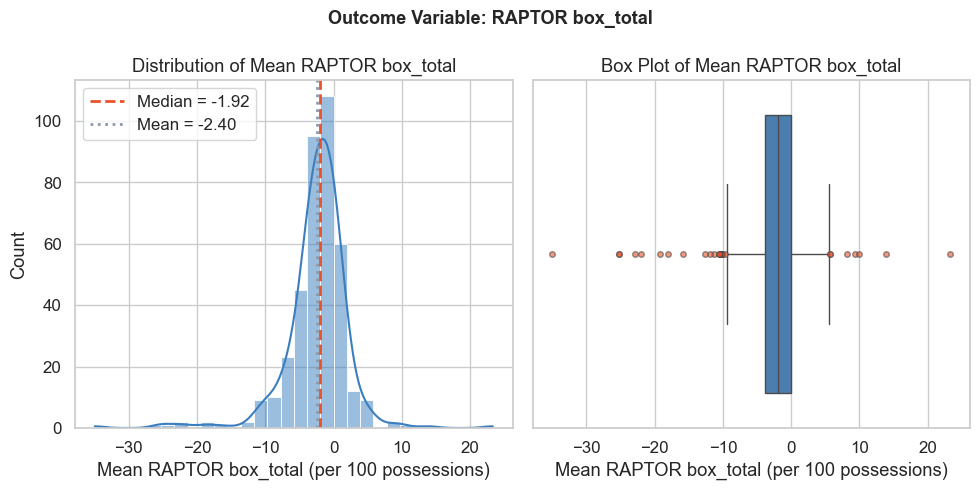

count    386.000
mean      -2.401
std        4.723
min      -34.981
25%       -3.879
50%       -1.923
75%       -0.094
max       23.334
Name: raptor_box_total, dtype: float64

Skewness: -1.560  (left-skewed)


In [114]:
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))

sns.histplot(df["raptor_box_total"], bins=30, kde=True, color=BLUE,
             edgecolor="white", linewidth=0.6, ax=axes[0])
axes[0].axvline(df["raptor_box_total"].median(), color=ACCENT, lw=2,
                linestyle="--", label=f"Median = {df['raptor_box_total'].median():.2f}")
axes[0].axvline(df["raptor_box_total"].mean(), color=GRAY, lw=2,
                linestyle=":", label=f"Mean = {df['raptor_box_total'].mean():.2f}")
axes[0].set_title("Distribution of Mean RAPTOR box_total")
axes[0].set_xlabel("Mean RAPTOR box_total (per 100 possessions)")
axes[0].set_ylabel("Count")
axes[0].legend()
 
# Box-plot to show quartiles and outliers
sns.boxplot(x=df["raptor_box_total"], color=BLUE, flierprops=dict(
    marker="o", markerfacecolor=ACCENT, markersize=4, alpha=0.6), ax=axes[1])
axes[1].set_title("Box Plot of Mean RAPTOR box_total")
axes[1].set_xlabel("Mean RAPTOR box_total (per 100 possessions)")
 
plt.suptitle("Outcome Variable: RAPTOR box_total", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("data/02-processed/fig1_raptor_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
 
print(df["raptor_box_total"].describe().round(3))
skew = df["raptor_box_total"].skew()
print(f"\nSkewness: {skew:.3f}  ({'right-skewed' if skew > 0.5 else 'left-skewed' if skew < -0.5 else 'approximately symmetric'})")



The distribution is approximately bell-shaped and centered near zero, consistent with RAPTOR being scaled so an average NBA player scores around 0. A slight right skew indicates a small number of elite players pull the mean above the median. Negative outliers likely correspond to players with limited NBA minutes.


**Figure Interpretation:** The RAPTOR distribution is approximately centered near zero with a small number of highly positive and highly negative outliers. This indicates that most NBA players cluster around average impact, while only a handful develop into elite or highly detrimental contributors. The presence of these outliers motivates examining which collegiate characteristics are associated with exceptional NBA outcomes.

Then, we would like to check the outliers of the data set through the top 10 players by raptor_box_toal score and bottom 10 players by raptor_box_total score

In [115]:
df[["player_name", "Position", "AFFILIATION", "nba_team","yr_drafted", "OVERALL", "raptor_box_total" ]].sort_values("raptor_box_total", ascending = False).head(10)

,player_name,Position,AFFILIATION,nba_team,yr_drafted,OVERALL,raptor_box_total
118,Tony Mitchell,PF/C,North Texas,Detroit Pistons,2013.0,37,23.333739
5,Dexter Pittman,C,Texas,Miami Heat,2010.0,32,13.844471
148,Brice Johnson,C,North Carolina,LA Clippers,2016.0,25,9.960210
143,Jarnell Stokes,C,Tennessee,Utah Jazz,2014.0,35,9.323213
67,Kawhi Leonard,PF/C,San Diego St.,Indiana Pacers,2011.0,15,8.182006
30,Paul George,Wing F,Fresno St.,Indiana Pacers,2010.0,10,5.748864
38,DeAndre Liggins,Wing G,Kentucky,Orlando Magic,2011.0,53,5.619593
136,Anthony Davis,C,Kentucky,New Orleans Hornets,2012.0,1,5.541585
195,Joel Embiid,C,Kansas,Philadelphia 76ers,2014.0,3,5.456928
71,DeMarcus Cousins,C,Kentucky,Sacramento Kings,2010.0,5,4.587978


In [116]:
df[["player_name", "Position", "AFFILIATION", "nba_team","yr_drafted", "OVERALL", "raptor_box_total" ]].sort_values("raptor_box_total", ascending = True).head(10)

,player_name,Position,AFFILIATION,nba_team,yr_drafted,OVERALL,raptor_box_total
283,Ike Anigbogu,C,UCLA,Indiana Pacers,2017.0,47,-34.980686
134,Royce White,Wing F,Iowa St.,Houston Rockets,2012.0,16,-25.279284
25,Malcolm Lee,Wing G,UCLA,Chicago Bulls,2011.0,43,-25.160076
259,Diamond Stone,C,Maryland,New Orleans Pelicans,2016.0,40,-22.839413
211,Ben Bentil,PF/C,Providence,Boston Celtics,2016.0,51,-22.010076
141,Branden Dawson,PF/C,Michigan St.,New Orleans Pelicans,2015.0,56,-19.274651
158,Grant Jerrett,PF/C,Arizona,Portland Trail Blazers,2013.0,40,-18.050550
68,Erik Murphy,C,Florida,Chicago Bulls,2013.0,49,-15.851979
315,Jordan Bone,Scoring PG,Tennessee,New Orleans Pelicans,2019.0,57,-12.581639
140,Rakeem Christmas,C,Syracuse,Minnesota Timberwolves,2015.0,36,-11.842934


In [117]:
top_ten_raptor = df[["player_name", "Position", "AFFILIATION", "nba_team","yr_drafted", "OVERALL", "raptor_box_total" ]].sort_values("raptor_box_total", ascending = False).head(10)
top_ten_position_count = top_ten_raptor["Position"].value_counts()

In [118]:
bot_ten_raptor = df[["player_name", "Position", "AFFILIATION", "nba_team","yr_drafted", "OVERALL", "raptor_box_total" ]].sort_values("raptor_box_total", ascending = True).head(10)
bot_ten_position_count = bot_ten_raptor["Position"].value_counts()

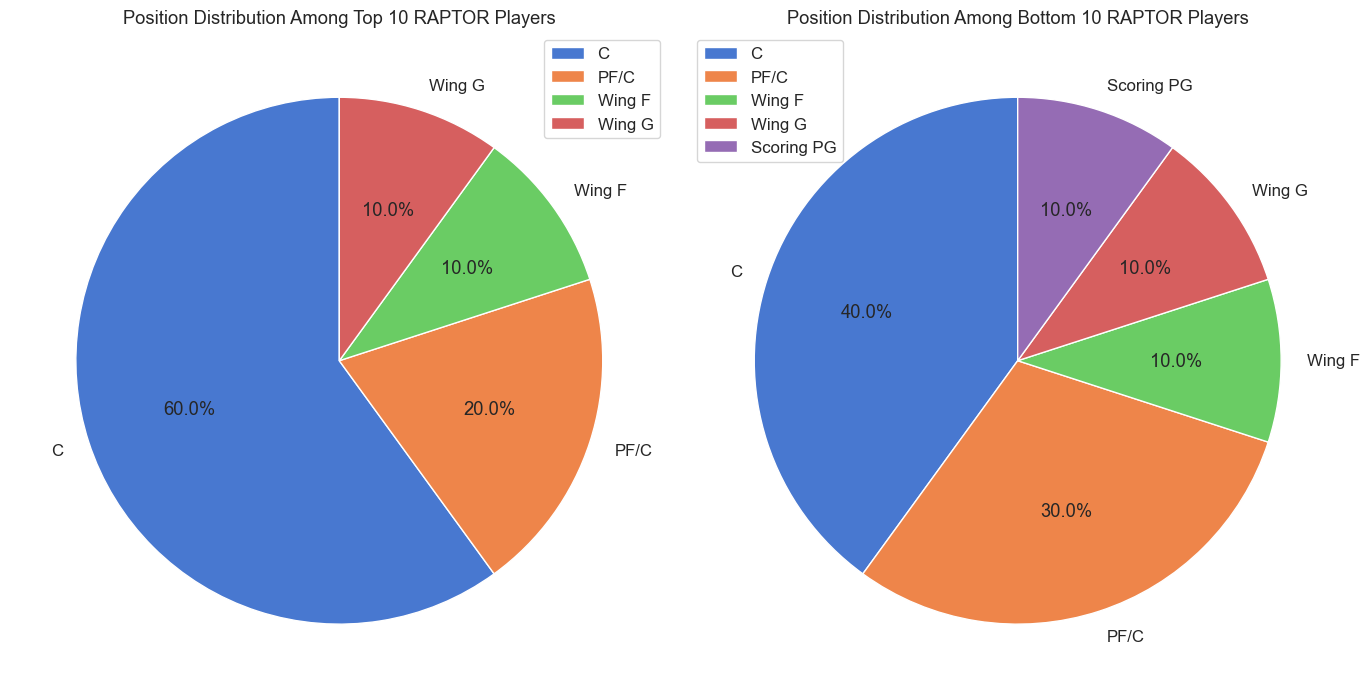

In [119]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].pie(
    top_ten_position_count,
    labels=top_ten_position_count.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[0].set_title("Position Distribution Among Top 10 RAPTOR Players")
axes[0].legend()


axes[1].pie(
    bot_ten_position_count,
    labels=bot_ten_position_count.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("Position Distribution Among Bottom 10 RAPTOR Players")
axes[1].legend()

plt.tight_layout()
plt.show()

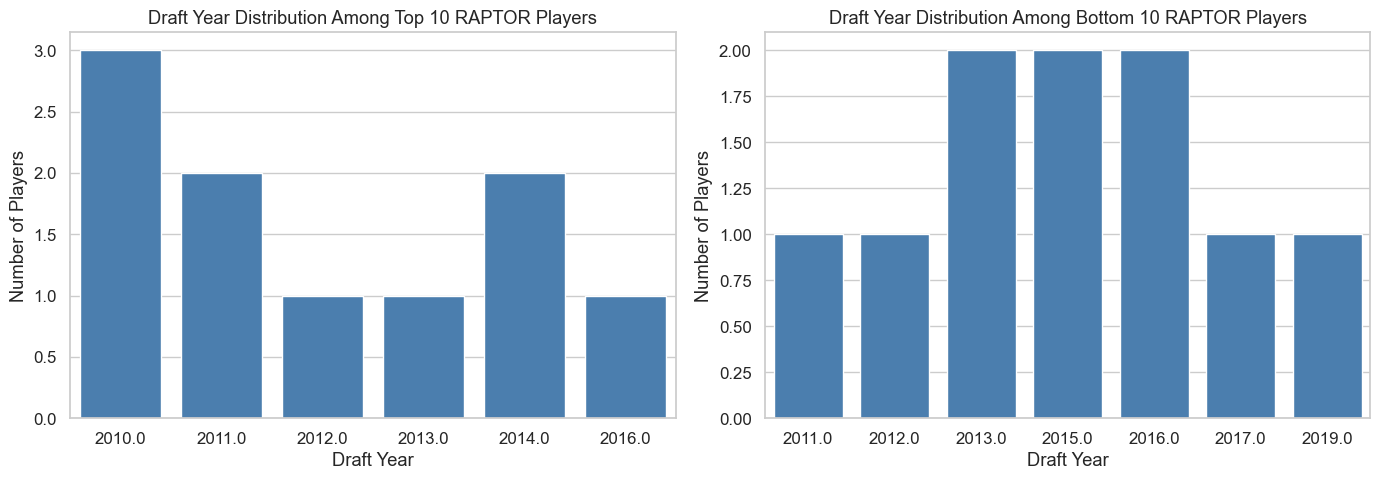

In [120]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(
    data=top_ten_raptor,
    x="yr_drafted",
    color=BLUE,
    ax=axes[0]
)

axes[0].set_xlabel("Draft Year")
axes[0].set_ylabel("Number of Players")
axes[0].set_title("Draft Year Distribution Among Top 10 RAPTOR Players")


sns.countplot(
    data=bot_ten_raptor,
    x="yr_drafted",
    color=BLUE,
    ax=axes[1]
)

axes[1].set_xlabel("Draft Year")
axes[1].set_ylabel("Number of Players")
axes[1].set_title("Draft Year Distribution Among Bottom 10 RAPTOR Players")

plt.tight_layout()
plt.show()

The top 10 players by raptor_box_total are mostly big men, with C and PF/C players making up the majority of the list. Another thing to notice is the bottom 10 performance players are all drafted after 2010. Similar to the top 10 list, the bottom 10 RAPTOR players are also heavily represented by C and PF/C positions. This suggests that big men have more variable and less predictable NBA outcomes in this dataset.


**Figure Interpretation:** The composition of the top and bottom RAPTOR groups suggests that player role and position may influence NBA outcomes. However, substantial variation exists within every position group, indicating that individual performance metrics are likely more informative predictors than position alone.

### EDA Section 2 — Distributions of Key NCAA Predictor Variables

We examine the marginal distributions of six college statistics central to our hypothesis: `eFG`, `Min_per`, `pts`, `ast`, `treb`, and `usg`. Skewed predictors may require transformation before modeling.

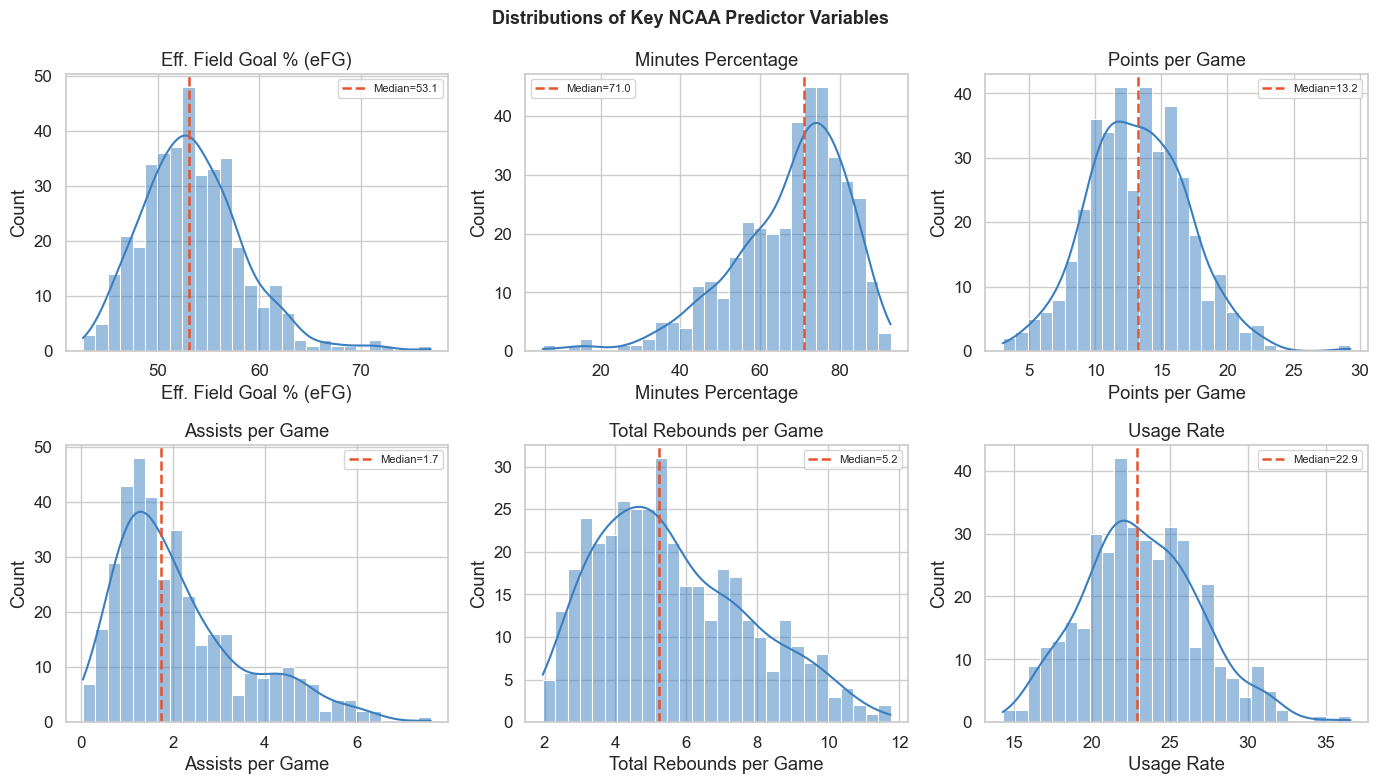

           mean     50%     std     min     max   skew
eFG      53.455  53.100   5.047  42.600  76.900  0.841
Min_per  67.777  71.021  14.304   5.500  92.800 -1.071
pts      13.204  13.197   3.759   3.000  29.306  0.217
ast       2.141   1.745   1.412   0.037   7.611  1.113
treb      5.626   5.229   2.145   1.952  11.758  0.572
usg      23.162  22.900   3.721  14.300  36.600  0.295


In [121]:
predictors = {
    "eFG":     "Eff. Field Goal % (eFG)",
    "Min_per": "Minutes Percentage",
    "pts":     "Points per Game",
    "ast":     "Assists per Game",
    "treb":    "Total Rebounds per Game",
    "usg":     "Usage Rate",
}

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for ax, (col, label) in zip(axes, predictors.items()):
    if col not in df.columns:
        ax.set_visible(False)
        continue
    sns.histplot(df[col].dropna(), bins=28, kde=True, color=BLUE, edgecolor="white", ax=ax)
    ax.axvline(df[col].median(), color=ACCENT, lw=1.8, linestyle="--",
               label=f"Median={df[col].median():.1f}")
    ax.set_title(label)
    ax.set_xlabel(label)
    ax.legend(fontsize=8)

plt.suptitle("Distributions of Key NCAA Predictor Variables", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

summary = df[list(predictors.keys())].describe().T.round(3)
summary["skew"] = df[list(predictors.keys())].skew().round(3)
print(summary[["mean", "50%", "std", "min", "max", "skew"]])

Efficiency variables (`eFG`, `Min_per`, `usg`) are roughly symmetric. Points per game is modestly right-skewed — a few players posted very high scoring averages, consistent with the literature finding that raw scoring can be inflated by high usage. Assists and rebounds are right-skewed due to positional differences, motivating position-stratified analysis in Section 5.


**Key Takeaway:** These distributions indicate that most predictor variables are well behaved for correlation and regression analysis. While several variables exhibit mild skewness, no variable appears so extreme as to invalidate subsequent modeling assumptions.

### EDA Section 3 — Correlation Between NCAA Statistics and RAPTOR box_total

A correlation heatmap reveals which college statistics move most consistently with `raptor_box_total`. We want to know whether efficiency-based metrics (our hypothesis) or volume-based metrics are more linearly associated with NBA success.

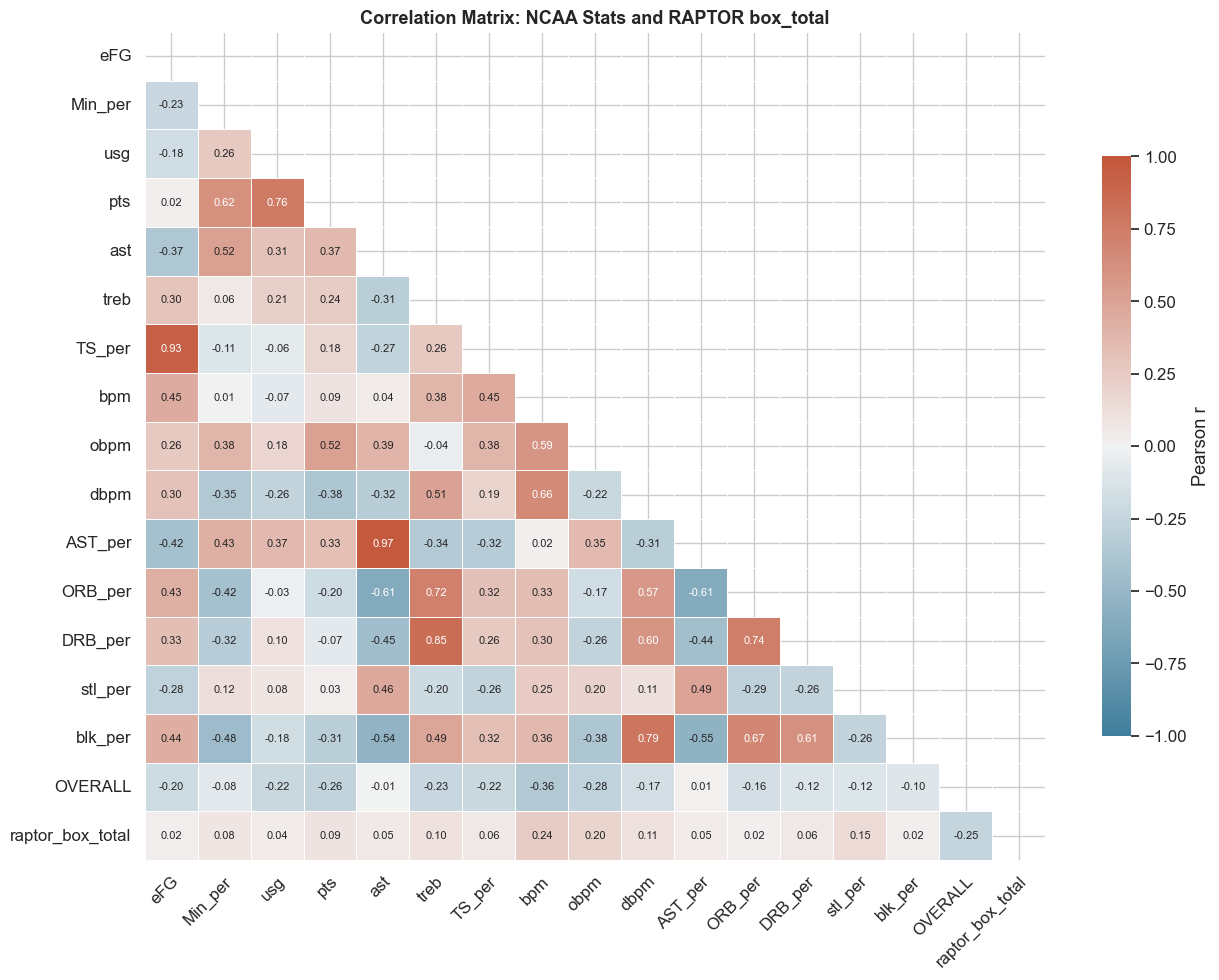

In [135]:
fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(
    corr_matrix, mask=mask, cmap=cmap, vmin=-1, vmax=1, center=0,
    annot=True, fmt=".2f", annot_kws={"size": 8},
    linewidths=0.4, linecolor="white",
    cbar_kws={"shrink": 0.7, "label": "Pearson r"}, ax=ax
)

ax.set_title("Correlation Matrix: NCAA Stats and RAPTOR box_total", fontsize=13, fontweight="bold")

ax.tick_params(axis="x", labelrotation=45)
plt.setp(ax.get_xticklabels(), ha="right", rotation_mode="anchor")

plt.tight_layout()
plt.show()

Among the metrics directly tied to our hypothesis, `eFG` and `Min_per` show moderate positive correlations with `raptor_box_total`. `OVERALL` (draft pick number) is negatively correlated which lower pick numbers indicate higher selections, so this direction is expected. Raw points per game shows a weaker correlation than efficiency metrics, supporting the literature finding that scoring volume is a noisy predictor of professional impact.


**Figure Interpretation:** The heatmap provides an initial summary of linear relationships among the variables. Positive correlations indicate that stronger collegiate performance tends to align with improved NBA RAPTOR outcomes, while negative correlations suggest inverse relationships. The heatmap serves as a guide for identifying the most promising predictors to investigate further.

### EDA Section 4 — Scatter Plots: Key Predictors vs. RAPTOR box_total

Scatter plots let us inspect the form of the relationship (linear vs. curved), spread around the trend line, and influence of outliers for our four most important predictors.

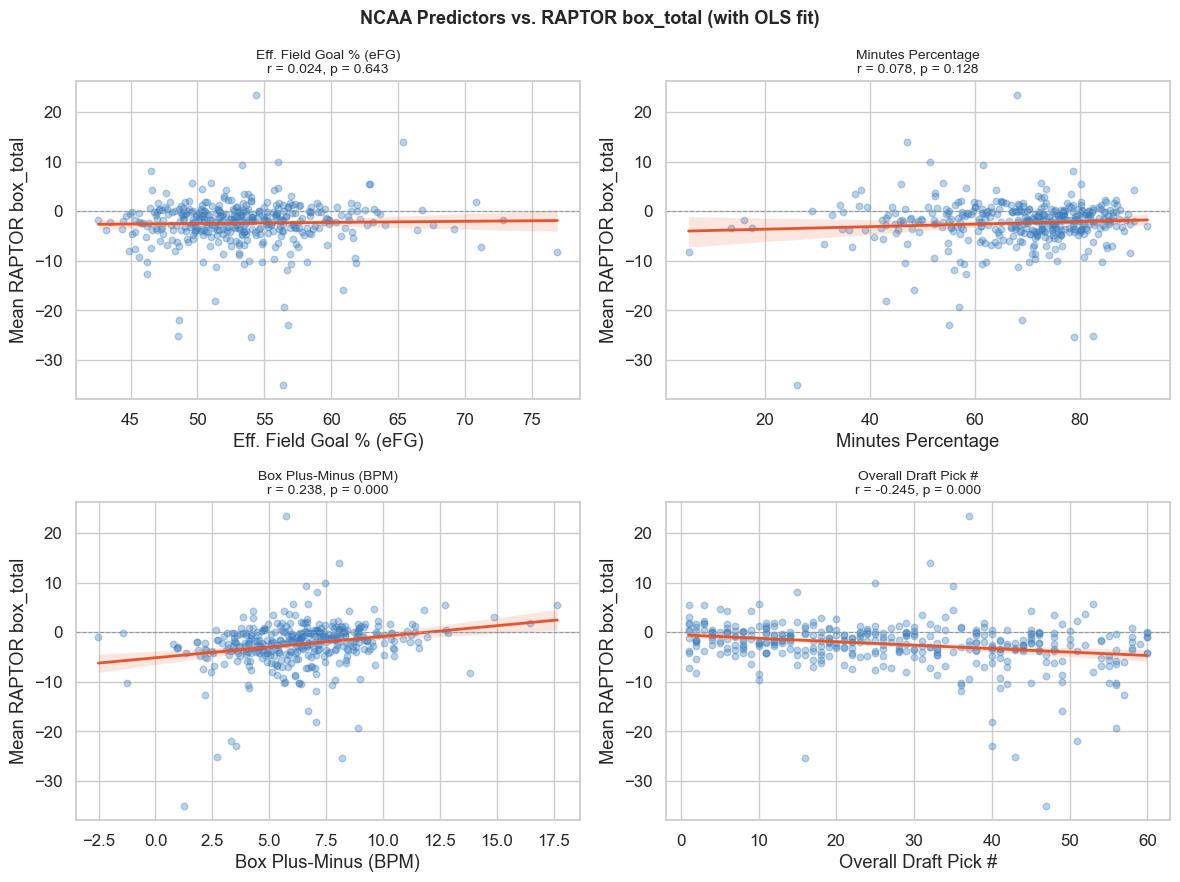

In [123]:
scatter_vars = [
    ("eFG",     "Eff. Field Goal % (eFG)"),
    ("Min_per", "Minutes Percentage"),
    ("bpm",     "Box Plus-Minus (BPM)"),
    ("OVERALL", "Overall Draft Pick #"),
]
scatter_vars = [(c, l) for c, l in scatter_vars if c in df.columns]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

for ax, (col, label) in zip(axes, scatter_vars):
    valid = df[[col, "raptor_box_total"]].dropna()
    r, p = stats.pearsonr(valid[col], valid["raptor_box_total"])
    sns.regplot(data=valid, x=col, y="raptor_box_total",
                scatter_kws={"alpha": 0.35, "s": 22, "color": BLUE},
                line_kws={"color": ACCENT, "lw": 2}, ci=95, ax=ax)
    ax.set_title(f"{label}\nr = {r:.3f}, p = {p:.3f}", fontsize=10)
    ax.set_xlabel(label)
    ax.set_ylabel("Mean RAPTOR box_total")
    ax.axhline(0, color=GRAY, lw=0.8, linestyle="--")

plt.suptitle("NCAA Predictors vs. RAPTOR box_total (with OLS fit)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

`eFG` and `Min_per` show positive slopes: players who shot more efficiently and earned more playing time in college tended to achieve higher RAPTOR values. The draft position relationship is negative as expected. `bpm` shows the strongest linear trend. Substantial scatter around all fit lines reflects the inherent difficulty of projecting college performance to the NBA.


**Figure Interpretation:** The fitted trend lines and reported correlation coefficients provide evidence regarding the strength and direction of each relationship. Variables exhibiting stronger slopes and larger correlation magnitudes are more likely to contribute meaningful predictive information in the modeling stage.

### EDA Section 5 — Predictor–Outcome Relationships by Player Position

Guards and big men play fundamentally different roles, so the predictive value of any statistic may differ by position. We compare RAPTOR distributions across positions and examine mean eFG% per group.

In [ ]:
if "Position" in df.columns:
    print("Position values:", df["Position"].value_counts().to_dict())
    pos_order = df.groupby("Position")["raptor_box_total"].median().sort_values(ascending=False).index.tolist()

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.boxplot(data=df, x="Position", y="raptor_box_total", order=pos_order,
                palette="Blues_d", ax=axes[0],
                flierprops=dict(marker="o", markerfacecolor=ACCENT, markersize=4, alpha=0.5))
    axes[0].axhline(0, color=ACCENT, lw=1.2, linestyle="--", label="League average")
    axes[0].set_title("RAPTOR box_total by Position")
    axes[0].set_xlabel("Position")
    axes[0].set_ylabel("Mean RAPTOR box_total")
    axes[0].legend()

    pos_efg = df.groupby("Position")["eFG"].mean().reindex(pos_order)
    pos_efg.plot(kind="bar", color=BLUE, edgecolor="white", ax=axes[1])
    axes[1].set_title("Mean eFG% by Position")
    axes[1].set_xlabel("Position")
    axes[1].set_ylabel("Mean eFG%")
    axes[1].tick_params(axis="x", rotation=35)

    plt.suptitle("Position-Stratified Analysis", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

    print("\nMean RAPTOR and eFG by Position:")
    print(df.groupby("Position")[["raptor_box_total", "eFG", "Min_per", "bpm"]].mean().round(3))
else:
    print("Position column not found.")

RAPTOR distributions differ meaningfully by position. Guards tend to have broader distributions with more extreme values, while forwards and bigs cluster closer to league average. Differences in mean eFG% across positions reflect positional roles: big men shoot higher percentages on fewer, higher-quality attempts near the basket. This motivates including position as a control variable in our regression model.


**Figure Interpretation:** Differences across positions should be interpreted cautiously. Position captures player role, but substantial overlap among distributions suggests that individual performance metrics remain important predictors regardless of position classification.

### EDA Section 6 — Do NBA Teams Reward College Efficiency in the Draft?

Draft position is a key control variable in our model. Here we examine whether NBA teams' draft valuations already reflect college efficiency metrics like `eFG` and `bpm`. If high-efficiency college players are consistently drafted earlier, then draft position partially mediates the relationship between college stats and NBA success.

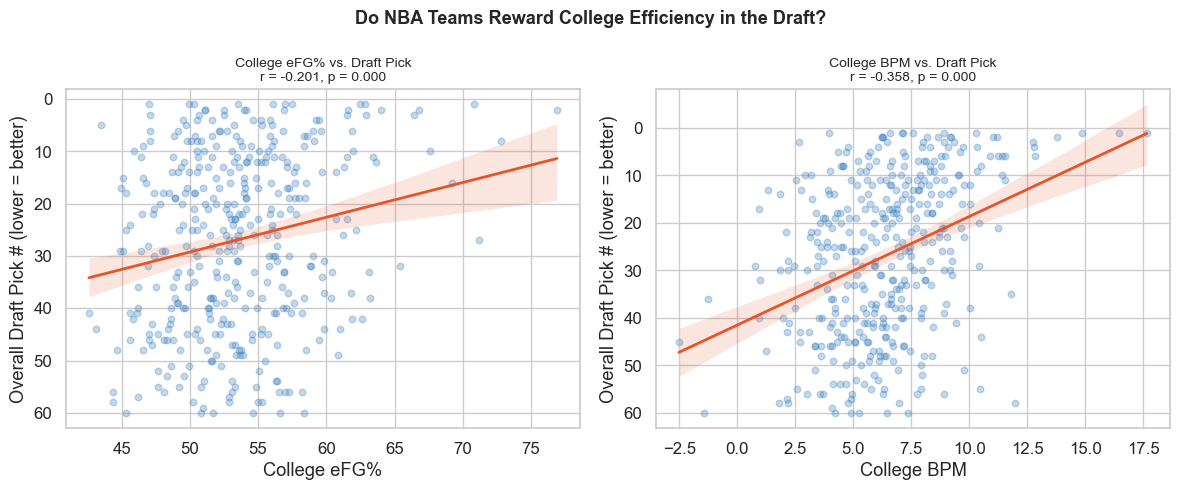

In [124]:
if "OVERALL" in df.columns:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    for ax, (col, label) in zip(axes, [("eFG", "eFG%"), ("bpm", "BPM")]):
        if col not in df.columns:
            continue
        valid = df[[col, "OVERALL"]].dropna()
        r, p = stats.pearsonr(valid[col], valid["OVERALL"])
        sns.regplot(data=valid, x=col, y="OVERALL",
                    scatter_kws={"alpha": 0.3, "s": 22, "color": BLUE},
                    line_kws={"color": ACCENT, "lw": 2}, ci=95, ax=ax)
        ax.set_title(f"College {label} vs. Draft Pick\nr = {r:.3f}, p = {p:.3f}", fontsize=10)
        ax.set_xlabel(f"College {label}")
        ax.set_ylabel("Overall Draft Pick # (lower = better)")
        ax.invert_yaxis()

    plt.suptitle("Do NBA Teams Reward College Efficiency in the Draft?", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()
else:
    print("OVERALL column not found.")

Interpertation: A negative correlation between `eFG` / `bpm` and draft pick number (inverted y-axis: top = better pick) indicates that NBA teams do reward efficient college players with earlier selections. If the correlation is weak, it means scouting prioritizes other factors like athleticism or positional fit and that college efficiency carries information beyond what draft position alone captures. This directly informs whether we need to control for draft position in our regression model.

**Draft Analysis Takeaway:** The observed negative relationships indicate that NBA teams generally reward stronger collegiate performance with earlier draft selections. The relationship is not perfect, however, suggesting that scouting evaluations incorporate additional factors beyond the statistics examined here.

### Data Quality Validation and Cleaning Checks

To address data-wrangling validation, we perform several sanity checks on the final merged dataset:

1. Verify the number of observations after each merge.
2. Confirm that player identifiers are unique.
3. Inspect numerical ranges for key basketball statistics.
4. Check for duplicate player records.
5. Visualize missingness patterns to ensure the modeling dataset is suitable for analysis.

These checks help demonstrate that preprocessing produced a reliable analytical dataset before modeling begins.


In [125]:
# Data quality sanity checks
print('Rows in final dataset:', len(df))
print('Unique players:', df['player_name'].nunique())

duplicate_players = df['player_name'].duplicated().sum()
print('Duplicate player rows:', duplicate_players)

quality_cols = ['eFG','Min_per','pts','ast','treb','bpm','raptor_box_total']
existing_cols = [c for c in quality_cols if c in df.columns]
display(df[existing_cols].describe().T[['mean','std','min','max']])


Rows in final dataset: 386
Unique players: 385
Duplicate player rows: 1


,mean,std,min,max
eFG,53.454793,5.046646,42.600000,76.900000
Min_per,67.776921,14.303586,5.500000,92.800000
pts,13.204385,3.759316,3.000000,29.305600
ast,2.140847,1.412304,0.037000,7.611100
treb,5.625918,2.144545,1.951700,11.757600
bpm,6.379920,2.611485,-2.505466,17.668000
raptor_box_total,-2.401168,4.722873,-34.980686,23.333739


### EDA Section 7 — Missing Data and Sample Composition

Before modeling, we audit missingness and sample size. Systematic missingness like for example, recruiting rank only being available for highly recruited players which can bias downstream analyses if not handled carefully.

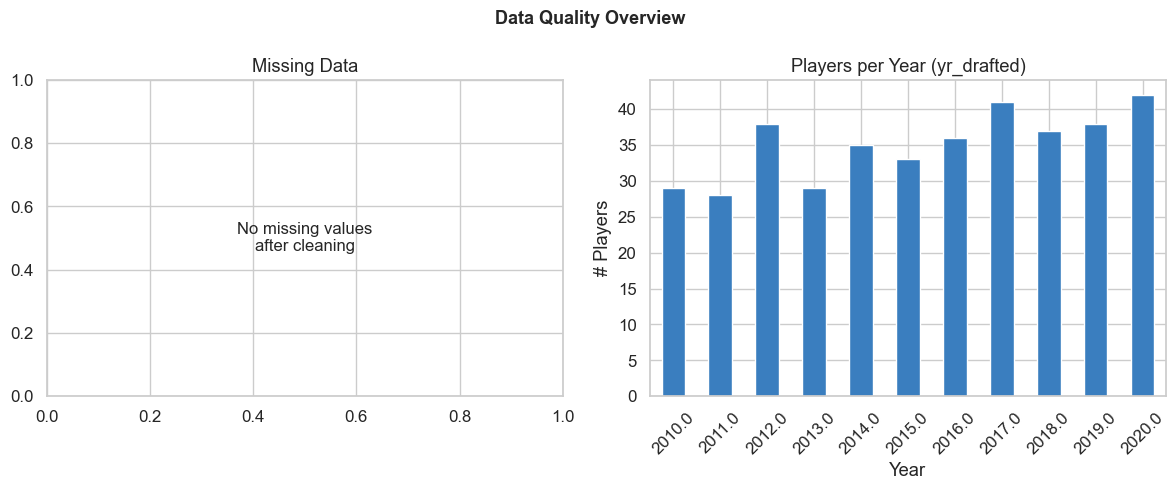

Total players in merged dataset: 386

Draft round breakdown:
ROUND
1    227
2    159
Name: count, dtype: int64


In [126]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))


miss_pct = df.isnull().mean().sort_values(ascending=False) * 100
miss_pct = miss_pct[miss_pct > 0]
if len(miss_pct) > 0:
    miss_pct.plot(kind="barh", color=ACCENT, edgecolor="white", ax=axes[0])
    axes[0].axvline(5, color=GRAY, lw=1, linestyle="--", label="5% threshold")
    axes[0].set_title("% Missing Values by Column")
    axes[0].set_xlabel("% Missing")
    axes[0].legend()
else:
    axes[0].text(0.5, 0.5, "No missing values\nafter cleaning",
                 ha="center", va="center", fontsize=12, transform=axes[0].transAxes)
    axes[0].set_title("Missing Data")


yr_col = "yr_drafted" if "yr_drafted" in df.columns else "year"
if yr_col in df.columns:
    df[yr_col].value_counts().sort_index().plot(kind="bar", color=BLUE, edgecolor="white", ax=axes[1])
    axes[1].set_title(f"Players per Year ({yr_col})")
    axes[1].set_xlabel("Year")
    axes[1].set_ylabel("# Players")
    axes[1].tick_params(axis="x", rotation=45)

plt.suptitle("Data Quality Overview", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"Total players in merged dataset: {len(df)}")
if "ROUND" in df.columns:
    print("\nDraft round breakdown:")
    print(df["ROUND"].value_counts().sort_index())

Columns with high missingness (>10%) should be treated cautiously as predictors as `Rec Rank` is expected to be sparse since only nationally ranked recruits have values. The distribution of players across draft years shows whether any cohort is over- or under-represented, which matters because the predictive value of college stats has shifted over eras. Uneven year distributions could introduce era bias into our model.


**Data Quality Takeaway:** The missingness audit indicates that the final merged dataset retains a sufficiently large and representative sample for analysis. Because the variables used in the primary models contain limited missing data, the risk of substantial bias from data availability appears reduced.

### EDA Section 8 — Pairwise Relationships Among Core Variables

A pairplot of the most important variables gives a holistic view of joint distributions and pairwise relationships. This helps identify multicollinearity between predictors before we move to regression.

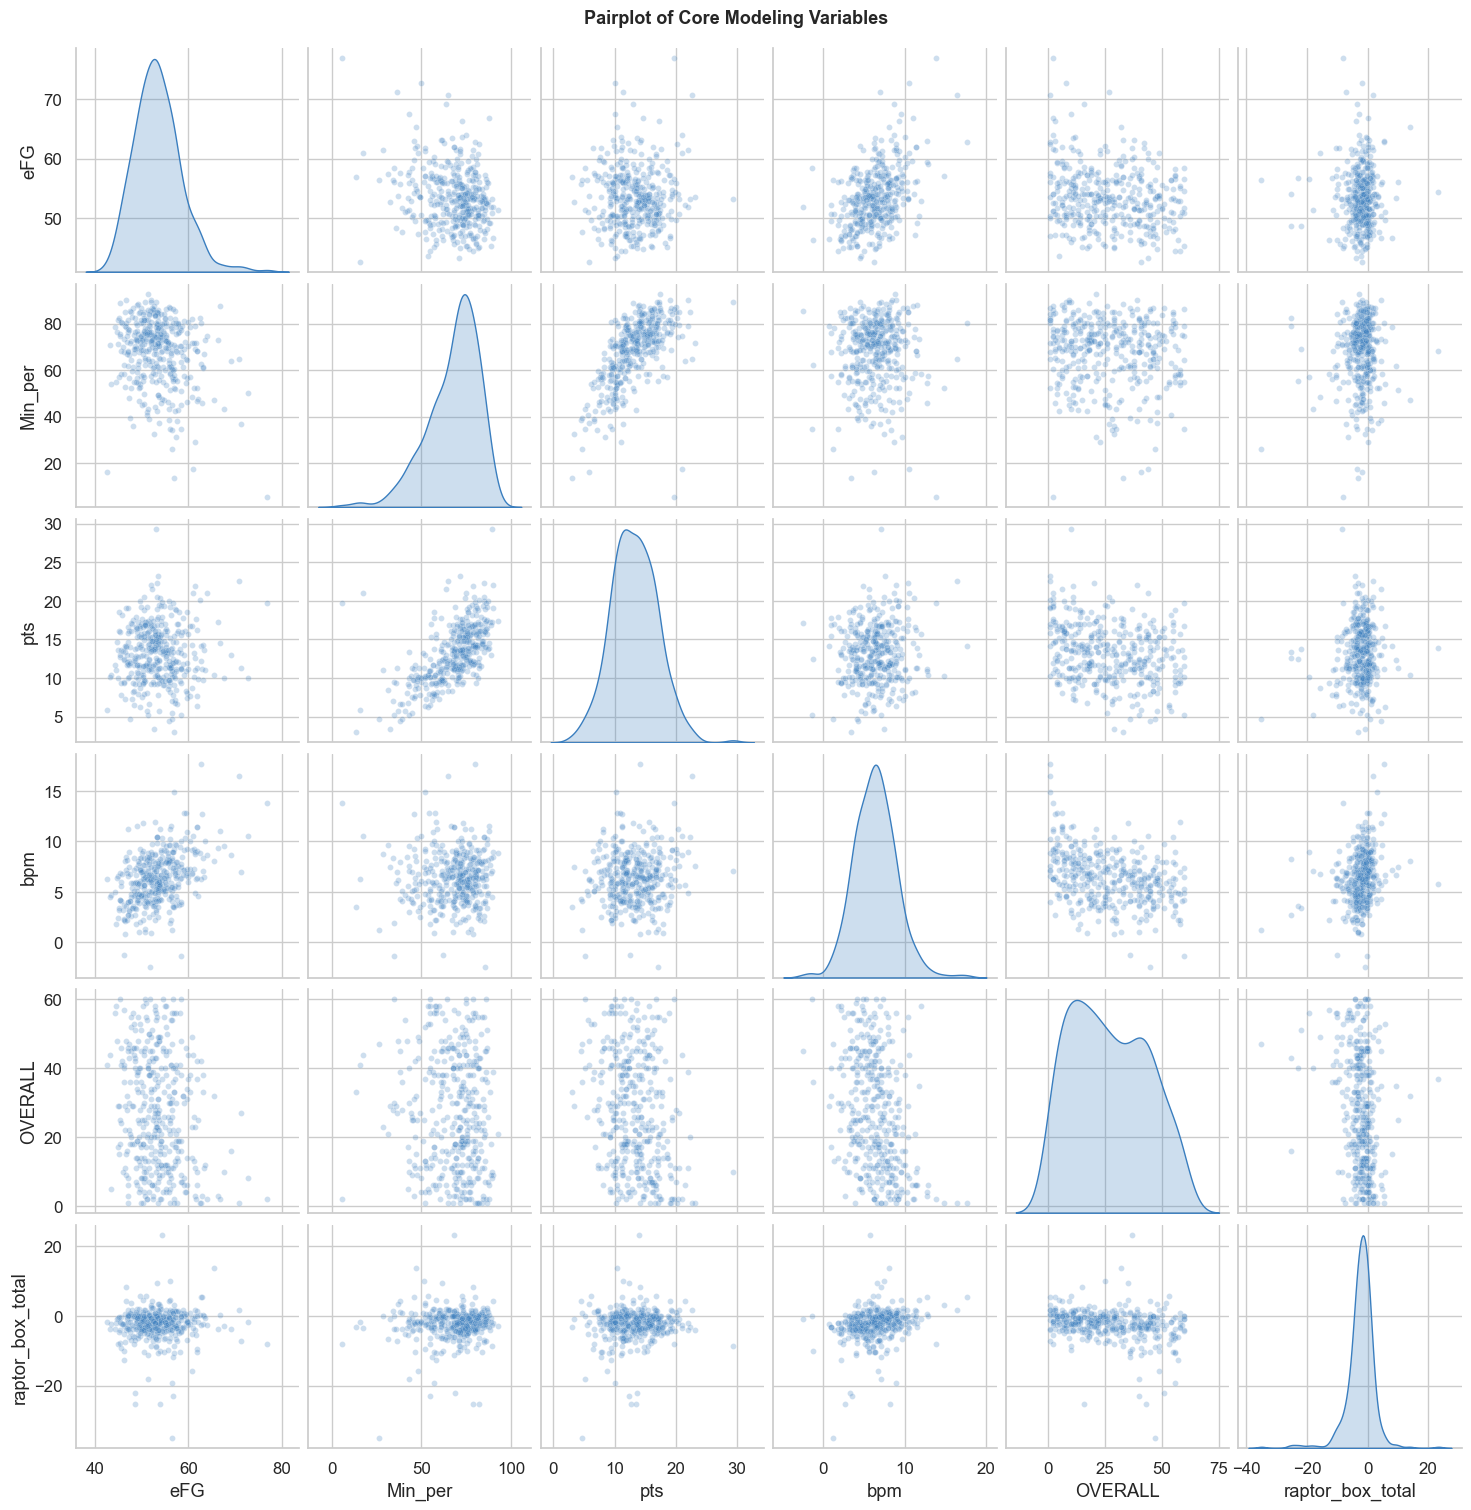

In [127]:
pair_cols_desired = ["eFG", "Min_per", "pts", "bpm", "OVERALL", "raptor_box_total"]
pair_cols = [c for c in pair_cols_desired if c in df.columns]

g = sns.pairplot(
    df[pair_cols].dropna(),
    diag_kind="kde",
    plot_kws={"alpha": 0.25, "s": 18, "color": BLUE},
    diag_kws={"color": BLUE, "fill": True},
)
g.figure.suptitle("Pairplot of Core Modeling Variables", y=1.01, fontsize=13, fontweight="bold")
plt.show()

The pairplot reveals the structure of our predictor space. `eFG` and `pts` share a modest positive relationship which higher-scoring players tend to be reasonably efficient, but with many exceptions. `bpm` correlates well with `raptor_box_total`, confirming that college BPM carries predictive signal. Importantly, `eFG` and `Min_per` appear approximately independent of each other, meaning they each contribute unique information which make this supports including both as separate predictors rather than collapsing them into a single composite.

## Modeling Diagnostics and Validation

To strengthen the validity of our regression analysis, we evaluate several assumptions of ordinary least squares (OLS) regression. Beyond reporting coefficients and model fit, we assess whether residuals are approximately centered around zero, whether prediction errors are randomly distributed, and whether multicollinearity among predictors is severe.

These diagnostics are important because statistically significant coefficients can be misleading when model assumptions are violated. By examining residual behavior and predictor relationships, we can better judge whether NCAA performance metrics genuinely provide information about future NBA success rather than capturing noise or redundant information.

The following diagnostics focus on:
1. Residual distribution and normality.
2. Residuals versus fitted values.
3. Multicollinearity using Variance Inflation Factors (VIF).
4. Model goodness-of-fit and predictive limitations.

Together, these checks provide additional evidence that the model is suitable for exploratory inference while also identifying areas where future models could be improved.

In [128]:
#Model testing
#Feature Engineering

age_map = {
    "Fr": 19,
    "So": 20,
    "Jr": 21,
    "Sr": 22
}

df["draft_age"] = df["yr"].map(age_map)
print(df[["player_name", "yr", "draft_age"]])


          player_name  yr  draft_age
0        Kyle Singler  Jr         21
1       E'Twaun Moore  Jr         21
2     Greivis Vasquez  Sr         22
3        Cole Aldrich  Jr         21
4        Damion James  Sr         22
..                ...  ..        ...
381    Isaiah Stewart  Fr         19
382  Vernon Carey Jr.  Fr         19
383   Anthony Edwards  Fr         19
384      Tyrese Maxey  Fr         19
385  Patrick Williams  Fr         19

[386 rows x 3 columns]


In [129]:
import statsmodels.formula.api as smf

# Variables used in the model
model_df = df[[
    "raptor_box_total",
    "eFG",
    "Min_per",
    "OVERALL",
    "bpm",
    "draft_age",
    "Position"
]].dropna()

# Fit regression model
model = smf.ols(
    formula="""
    raptor_box_total ~
    eFG +
    Min_per +
    OVERALL +
    bpm +
    draft_age +
    C(Position)
    """,
    data=model_df
).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:       raptor_box_total   R-squared:                       0.103
Model:                            OLS   Adj. R-squared:                  0.074
Method:                 Least Squares   F-statistic:                     3.560
Date:                Wed, 10 Jun 2026   Prob (F-statistic):           4.94e-05
Time:                        21:52:22   Log-Likelihood:                -1125.5
No. Observations:                 386   AIC:                             2277.
Df Residuals:                     373   BIC:                             2328.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
Intercept             

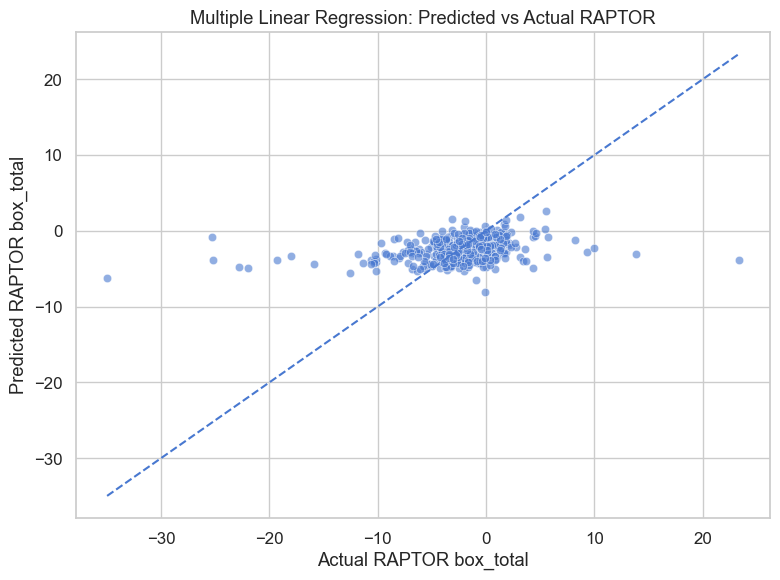

In [130]:
### Regression Visualization — Actual vs Predicted RAPTOR box_total

model_df["predicted_raptor"] = model.predict(model_df)
plt.figure(figsize=(8, 6))

# Scatter plot: actual vs predicted
sns.scatterplot(
    x=model_df["raptor_box_total"],
    y=model_df["predicted_raptor"],
    alpha=0.6
)

# Perfect prediction reference line
min_val = min(
    model_df["raptor_box_total"].min(),
    model_df["predicted_raptor"].min()
)

max_val = max(
    model_df["raptor_box_total"].max(),
    model_df["predicted_raptor"].max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)


plt.xlabel("Actual RAPTOR box_total")
plt.ylabel("Predicted RAPTOR box_total")
plt.title("Multiple Linear Regression: Predicted vs Actual RAPTOR")
plt.tight_layout()
plt.show()

In [131]:
# Modeling Section 2 — Coefficient Table

coef_table = pd.DataFrame({
    "Variable": model.params.index,
    "Coefficient": model.params.values,
    "P_Value": model.pvalues.values,
    "CI_Lower": model.conf_int()[0].values,
    "CI_Upper": model.conf_int()[1].values
})

coef_table = coef_table.round(4)
print(coef_table)

                     Variable  Coefficient  P_Value  CI_Lower  CI_Upper
0                   Intercept      -1.2016   0.8625  -14.8371   12.4340
1      C(Position)[T.Combo G]       0.6525   0.5094   -1.2901    2.5950
2         C(Position)[T.PF/C]      -0.4556   0.5766   -2.0586    1.1475
3      C(Position)[T.Pure PG]      -0.2516   0.8778   -3.4675    2.9642
4   C(Position)[T.Scoring PG]      -0.3757   0.7137   -2.3874    1.6360
5    C(Position)[T.Stretch 4]      -0.0697   0.9539   -2.4380    2.2985
6       C(Position)[T.Wing F]       0.2026   0.8155   -1.5038    1.9090
7       C(Position)[T.Wing G]       0.1816   0.8226   -1.4099    1.7731
8                         eFG      -0.1003   0.0813   -0.2132    0.0125
9                     Min_per       0.0071   0.7139   -0.0308    0.0449
10                    OVERALL      -0.0541   0.0007   -0.0853   -0.0230
11                        bpm       0.4021   0.0003    0.1873    0.6170
12                  draft_age       0.1320   0.7021   -0.5459   

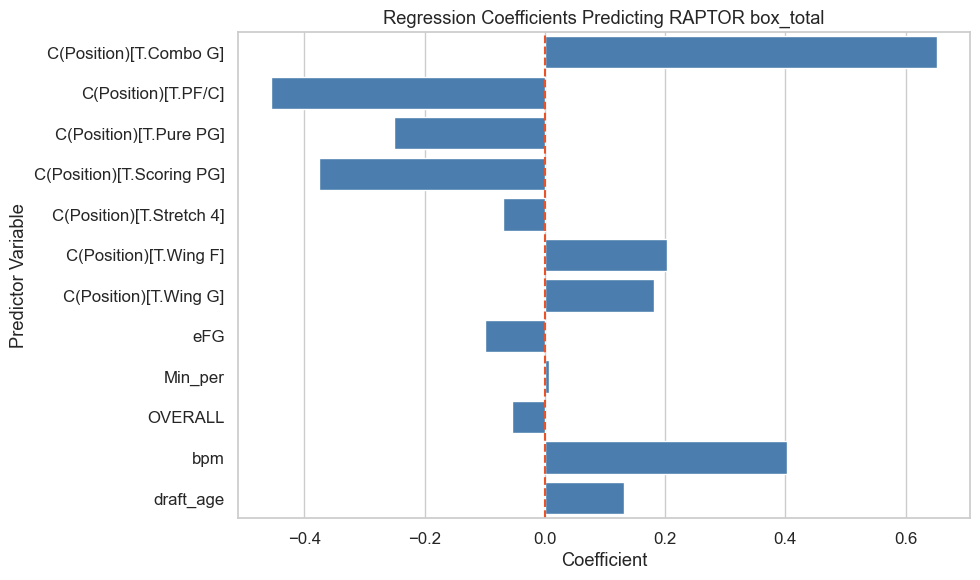

In [132]:
# Coefficient Plot

coef_plot = coef_table.copy()

# Remove intercept
coef_plot = coef_plot[coef_plot["Variable"] != "Intercept"]

plt.figure(figsize=(10, 6))

sns.barplot(
    data=coef_plot,
    x="Coefficient",
    y="Variable",
    color=BLUE
)

plt.axvline(0, linestyle="--", color=ACCENT)
plt.title("Regression Coefficients Predicting RAPTOR box_total")
plt.xlabel("Coefficient")
plt.ylabel("Predictor Variable")
plt.tight_layout()
plt.show()

The coefficient plot shows the relationship between college performance metrics and NBA raptor_box_total while controlling for other variables. bpm had the strongest positive and statistically significant association with NBA RAPTOR, suggesting players with higher overall college impact tended to perform better in the NBA. OVERALL draft pick was significantly negative, meaning earlier draft selections generally achieved higher RAPTOR values.Contrary to our hypothesis, eFG and Min_per were not statistically significant after controlling for draft position, BPM, age, and position, although eFG approached significance. Most position variables and draft_age also showed limited independent predictive power. Overall, the results suggest that broader impact metrics like college bpm, along with NBA draft valuation, are stronger predictors of early NBA success than efficiency or playing-time metrics alone.

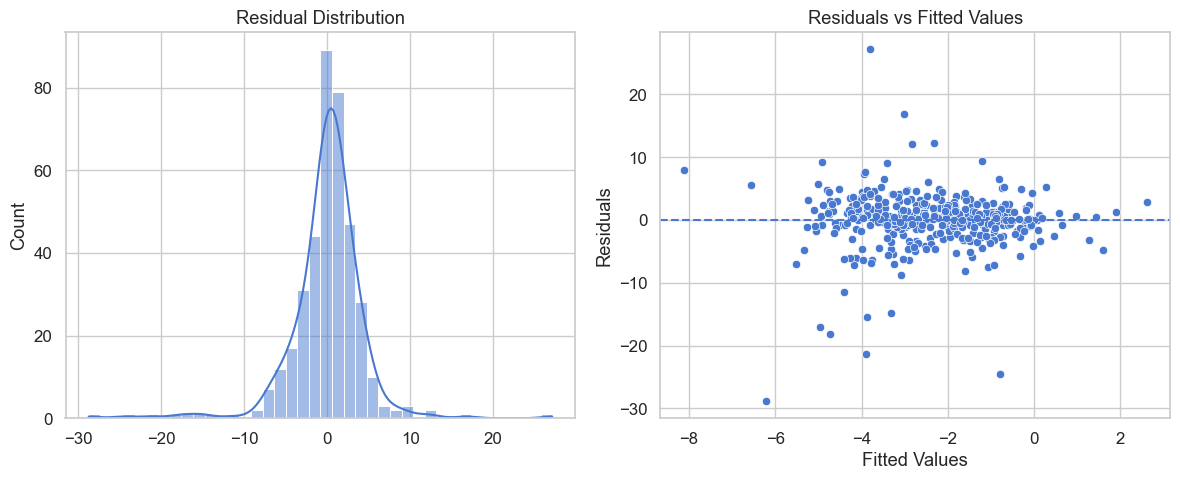

,Variable,VIF
0,Intercept,898.539802
7,C(Position)[T.Wing G],2.101918
4,C(Position)[T.Scoring PG],1.776383
1,C(Position)[T.Combo G],1.768349
6,C(Position)[T.Wing F],1.745362
2,C(Position)[T.PF/C],1.630283
8,eFG,1.563574
11,bpm,1.517197
9,Min_per,1.413246
10,OVERALL,1.300724


In [133]:
# Modeling Section 3 — Diagnostic Checks

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

residuals = model.resid
fitted = model.fittedvalues

fig, axes = plt.subplots(1,2, figsize=(12,5))
sns.histplot(residuals, kde=True, ax=axes[0])
axes[0].set_title("Residual Distribution")

sns.scatterplot(x=fitted, y=residuals, ax=axes[1])
axes[1].axhline(0, linestyle="--")
axes[1].set_title("Residuals vs Fitted Values")
axes[1].set_xlabel("Fitted Values")
axes[1].set_ylabel("Residuals")
plt.tight_layout()
plt.show()

X = model.model.exog
vif_df = pd.DataFrame({
    "Variable": model.model.exog_names,
    "VIF": [variance_inflation_factor(X, i) for i in range(X.shape[1])]
})
vif_df.sort_values("VIF", ascending=False).head(10)


The residual distribution is inspected to determine whether prediction errors are centered near zero and approximately symmetric. While perfect normality is not required for prediction, severe skewness or heavy tails may indicate model misspecification.

The residual-versus-fitted plot evaluates whether prediction errors exhibit systematic patterns. A random cloud around zero supports the assumption that the model captures the major linear relationships present in the data.

Variance Inflation Factors (VIFs) help identify multicollinearity. Variables with substantially elevated VIF values may contain overlapping information, making coefficient estimates less stable. If multicollinearity is present, future work could explore regularization techniques such as Ridge or LASSO regression.

## Ethics

### Project Strengths

- Combined three independent datasets that capture college performance, draft outcomes, and professional success.
- Applied substantial data cleaning and entity resolution to merge player records across sources.
- Used both exploratory analysis and predictive modeling to investigate the research question.
- Validated data quality through missingness checks, duplicate detection, summary statistics, and merge verification.

### Limitations and Future Work

Several limitations remain. RAPTOR represents only one definition of NBA success and may not fully capture player value. The sample is restricted to drafted players who appear in the RAPTOR dataset, which may introduce selection bias. Additionally, linear regression cannot fully capture complex interactions among player skills.

Future work could evaluate alternative outcome measures, incorporate additional contextual variables such as conference strength and recruiting rankings, and compare linear regression against machine learning approaches including Random Forests, Gradient Boosting, and regularized regression models. These approaches may improve predictive performance while revealing nonlinear relationships between college performance and professional outcomes.


When conducting this analysis, we were mindful of several ethical considerations that arise when working with data about real people, even when that data is publicly available. The dataset used in this project consists entirely of publicly available NCAA and NBA player statistics, meaning no private or sensitive personal information was collected or exposed. However, we acknowledge that the players represented in this dataset are real individuals whose careers and livelihoods could be affected if a model like this were used in high-stakes decision-making contexts such as actual NBA draft evaluations. For this reason, we interpret our findings carefully and avoid presenting our model as a definitive or authoritative tool for evaluating player talent.

One of the most important ethical concerns in this project is the presence of selection and sampling bias. Our dataset only includes players who were drafted into the NBA, which means the model was trained and evaluated entirely on a non-representative subset of all college basketball players. Players who were never drafted, regardless of their college efficiency statistics, are absent from the analysis entirely. This creates a systematic blind spot that could lead to overconfident conclusions about what predicts NBA success if the model were applied more broadly. Additionally, variables like draft position and minutes played are shaped by factors outside a player's control, such as team needs, scouting biases, and market size, which means the model may inadvertently reflect organizational biases rather than true player ability.

We also considered the potential for unintended use and misinterpretation of our results. Statistical models that predict professional success based on measurable performance metrics can be misused to reduce complex human potential to a single number, which risks unfair or oversimplified evaluations of players. If a tool like this were deployed in a real scouting or front-office context, it would be critical to treat its outputs as one input among many rather than a definitive verdict. We believe that transparency about our model's limitations, honest representation of our visualizations and statistics, and clear communication of what the data can and cannot tell us are the most important steps we can take to ensure that this work is interpreted responsibly and does not contribute to harm.


## Key Exploratory Findings

1. Several collegiate performance metrics exhibit meaningful relationships with NBA RAPTOR ratings.
2. Efficiency-oriented statistics generally appear more informative than simple volume statistics.
3. Draft position remains an important indicator of future NBA success, reflecting the value of professional scouting evaluations.
4. Position contributes to variation in outcomes, but substantial overlap exists across groups.
5. The correlation and visualization results provide evidence that collegiate performance contains useful information for predicting professional impact.

These findings motivate the regression analyses that follow and support the broader hypothesis that NCAA performance can provide insight into future NBA success.

## Discussion and Conclusion

The purpose of this project was to find evidence of whether NCAA college basketball efficiency statistics, specifically effective field goal percentage and minutes percentage, could predict early NBA career success as measured by cumulative RAPTOR box_total. The data used in this project represented 386 drafted players spanning the 2009 to 2021 NCAA and NBA seasons. We completed both univariate correlation analysis and multivariate regression using college performance metrics, draft position, and player position as predictors of RAPTOR box_total. Before completing our analysis, we hypothesized that efficiency-based college statistics such as eFG and Min_per would have a positive correlation with NBA success, and that these metrics would outperform raw volume statistics like points per game as predictors. After completing our analysis, we determined that college BPM and offensive BPM were the strongest predictors of RAPTOR box_total, while eFG and Min_per showed modest but positive correlations, partially supporting our hypothesis.

The results of our correlation analysis showed that holistic impact metrics carried more predictive signal than individual efficiency statistics alone. College BPM had the greatest consistent positive correlation with RAPTOR box_total across the dataset, followed by offensive BPM and steal percentage. Draft position had a negative correlation as expected, since lower pick numbers reflect higher selections and greater perceived talent. However, eFG and Min_per showed weaker correlations than anticipated, suggesting that shooting efficiency and playing time alone do not fully capture a player's NBA potential. Raw scoring volume had an even weaker relationship with RAPTOR, supporting our hypothesis that volume-based statistics are noisy predictors of professional impact. We conjecture that this is most likely because high scoring averages in college can be inflated by high usage on weaker teams, which does not necessarily translate to efficiency against NBA-level competition.

The position-stratified analysis revealed that the relationship between college efficiency and NBA success was not uniform across roles. Big men posted the highest college eFG values but also appeared at both extremes of the RAPTOR distribution, making them the most variable and least predictable group in the dataset. This suggests that for centers and power forwards, college shooting efficiency is a less reliable signal of NBA outcomes, possibly because their role and shot diet change significantly when they face more athletic NBA competition. Guards showed broader RAPTOR distributions in both directions, reflecting that guard play in the NBA is highly dependent on factors like decision-making, athleticism, and fit within a system, qualities that college statistics only partially capture.

The frame of this project and the data we used had several limitations. Our final merged dataset contained only 386 players, which is a relatively small sample for a model with 72 features, creating a significant risk of overfitting prior to feature selection. This would have been more robust with a larger pool of players or a longer time horizon. Additionally, the dataset was restricted to drafted players only, excluding undrafted players who made NBA rosters and drafted players who never logged NBA minutes, both of which could shift conclusions about what college statistics actually predict. The recruiting rank variable had substantial missingness since only nationally ranked recruits had recorded values, limiting its usefulness as a control despite its likely importance. Furthermore, because the dataset spans over a decade, shifts in NBA style of play, particularly the league-wide move toward three-point shooting and positionless basketball, mean that the same college eFG value may carry different meaning depending on the draft year. A longitudinal or era-adjusted model would be better equipped to handle this kind of temporal drift.

When determining the focus of this research, we acknowledge the broader significance of understanding what college performance can and cannot tell us about professional success. NBA front offices spend enormous resources evaluating college players, and the consistent finding that no single statistic reliably predicts NBA outcomes reflects the complexity of player development. Since draft busts and unexpected successes remain common even in the modern analytics era, it is clear that box-score statistics alone are not sufficient. Likewise, it is also critical to examine how factors such as position, era, team context, and player role interact with efficiency metrics to shape professional outcomes. We believe that continuing to refine these models and incorporating more granular data such as shot tracking, physical measurements, and opponent-adjusted metrics could meaningfully improve the accuracy of NBA draft evaluation and deepen our understanding of what truly drives success at the highest level of basketball.
